# SRE, Reliability, Security and FinOps for AI Systems

> **Who is this for:** engineers who already have an AI service running (a RAG API, a model endpoint, an agent) and now have to keep it **reliable, secure, compliant and affordable**. No SRE, security or finance background needed.
>
> **What you will learn:**
> - **SRE practice:** a short SLO and error-budget recap, **incident response** roles and **severity levels**, **on-call**, **runbooks**, **blameless postmortems** and **toil**
> - **chaos engineering:** principles, game days, tools (Chaos Mesh, LitmusChaos, AWS Fault Injection Service, Azure Chaos Studio, Gremlin), and a runnable failure-injection experiment on a simulated RAG service graph
> - **continuous profiling** (Pyroscope, Parca, OpenTelemetry Profiles) with a runnable `cProfile` example and a toy sampling profiler
> - **LLM observability:** OpenTelemetry **GenAI semantic conventions**, Langfuse / Phoenix / LangSmith, and a token, cost and latency dashboard built from fake spans
> - **security for AI deployments:** **zero trust**, identity-based access, **network segmentation**, **secrets and API-key rotation** (runnable simulation), **encryption** (envelope encryption toy), **CSPM / CNAPP** (a mini posture scanner)
> - **compliance in plain words:** SOC 2, ISO/IEC 27001, ISO/IEC 42001, HIPAA, GDPR, EU AI Act touchpoints, and **audit evidence collection** (not legal advice)
> - **FinOps:** Inform / Optimize / Operate, the FOCUS billing format, **cost allocation tags** with a tag-compliance and **showback** report, **unit economics**, **commitments vs spot**, **Kubernetes cost** (OpenCost, Kubecost), **off-hours shutdown**, **GPU idle detection**, LLM token budgets and cost anomalies
> - **serverless and edge for AI:** AWS Lambda, Azure Functions, Cloud Run functions, Cloudflare Workers / Workers AI, Vercel and Netlify functions, Supabase / Firebase as backends, **cold starts** (runnable simulation), limits, and when serverless fits
>
> **Prerequisites:** [Observability hands-on](16_observability_hands_on.ipynb) (logs, metrics, traces, SLOs, burn-rate alerts). Helpful: [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb), [Cloud cost optimization](../18_Cloud/04_cloud_cost_optimization.ipynb), [Cloud ML architecture and cost planning](../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb), [Designing for 100 million users](../22_ML_System_Design/12_designing_for_100_million_users.ipynb), [Linux, shell and networking](../23_Software_Engineering/13_linux_shell_and_networking_for_ai_engineers.ipynb).
>
> **Time needed:** about 4 hours to read and play. The code runs in under a minute.
>
> **Runs on:** CPU, no API key, no internet. Every company, bill, price, incident and resource in the code is **made up**. Prices are **illustrative units**, not real list prices. Cloud CLI and SDK snippets are shown as text and never executed.

## Explained simply

Shipping a model is the start, not the end. Four questions decide whether it survives in production:

| Question | Discipline | The one idea to remember |
|---|---|---|
| Does it keep working, and do we recover fast when it breaks? | **SRE** (site reliability engineering) | agree how reliable it must be (SLO), spend the remaining "error budget" on change, learn from every incident |
| Will it survive the failures we have not seen yet? | **Chaos engineering** | break things on purpose, in a controlled way, before reality does |
| Can attackers or mistakes leak data or keys? | **Security and compliance** | verify every request (zero trust), keep secrets short-lived, prove it to auditors with evidence |
| Can we afford it as it grows? | **FinOps** | every cost has an owner (tags), measure cost per unit of value, switch off what is idle |

```mermaid
flowchart LR
    U[Users] --> E[Edge / CDN / WAF]
    E --> G[API gateway + auth]
    G --> A[RAG / agent API]
    A --> C[(cache)]
    A --> V[(vector DB)]
    A --> L1[LLM provider A]
    A -. fallback .-> L2[LLM provider B]
    A --> M[self-hosted model on GPU]
    subgraph Ops[Run it well]
      O1[SLOs, on-call, postmortems]
      O2[chaos experiments]
      O3[traces + token cost dashboards]
      O4[zero trust, secrets, posture scans]
      O5[tags, showback, idle GPU shutdown]
    end
```

## 0. Setup

In [1]:
import math, random, time, json, hashlib, hmac, secrets, sys, threading, io, cProfile, pstats, re
from collections import Counter, defaultdict, deque
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 70)
print("ready, seed =", SEED)

ready, seed = 42


# Part A: Site reliability engineering

## 1. SLIs, SLOs and error budgets: a one-cell recap

The [observability notebook](16_observability_hands_on.ipynb) builds these step by step, including multi-window **burn-rate alerts**; [Designing for 100 million users](../22_ML_System_Design/12_designing_for_100_million_users.ipynb) covers availability targets and disaster recovery (RPO/RTO). In one breath:

- An **SLI** (service level indicator) is a measured ratio of good events, for example "requests that succeed in under 5 s / all requests".
- An **SLO** (objective) is the target for that ratio over a window, for example 99.5% over 30 days.
- The **error budget** is what is left: 0.5% of requests may be bad. While budget remains, ship features; when it is spent, slow down and fix reliability.
- An **SLA** (agreement) is a contract with penalties, and is usually looser than the internal SLO.

For AI services, add quality and cost SLIs: time to first token, groundedness or eval pass rate on sampled traffic, and cost per request.

In [2]:
def error_budget(slo, days=30, requests_per_day=None):
    minutes = (1 - slo) * days * 24 * 60
    out = {"SLO": f"{slo:.3%}", "bad minutes / 30 days": round(minutes, 1)}
    if requests_per_day:
        out["bad requests / 30 days"] = int(round((1 - slo) * days * requests_per_day))
    return out

print(pd.DataFrame([error_budget(s, requests_per_day=200_000) for s in (0.99, 0.995, 0.999, 0.9995, 0.9999)]).to_string(index=False))

    SLO  bad minutes / 30 days  bad requests / 30 days
99.000%                  432.0                   60000
99.500%                  216.0                   30000
99.900%                   43.2                    6000
99.950%                   21.6                    3000
99.990%                    4.3                     600


## 2. Incident response: roles, severity, on-call and runbooks

**What it is:** an **incident** is an unplanned event that hurts users or puts them at risk (outage, wrong answers at scale, data leak). **Incident response** is the agreed way to handle one so that people do not trip over each other.

**Simple analogy:** a fire brigade. One chief gives orders, firefighters work the hose, one person talks to the neighbours and the press. Nobody argues about who does what in the middle of the fire, because it was decided beforehand.

**Roles** (the Google SRE books describe these, based on the Incident Command System):

| Role | Does | Does not |
|---|---|---|
| **Incident Commander (IC)** | owns the incident, sets priorities, assigns work, decides when it is over | debug or type commands themself |
| **Operations Lead** | the only person (or team) changing production: rollback, failover, scaling | talk to stakeholders |
| **Communications Lead** | regular status updates to users, support, leadership; status page | change systems |
| **Planning Lead / Scribe** | keeps the timeline, tracks follow-ups, handles hand-offs | |
| **Subject matter experts** | join when paged for a component (vector DB, GPU cluster, LLM provider) | |

**Severity levels** (example scheme; each company defines its own):

| Level | Example for an AI product | Response |
|---|---|---|
| **SEV1** | chat API down for everyone; PII leaking in model answers; leaked production API key in use | page immediately, IC assigned, updates every 30 min, postmortem required |
| **SEV2** | one region or major feature down; p95 latency 5x; LLM provider outage with degraded fallback | page on-call, postmortem required |
| **SEV3** | minor feature broken; quality regression on a small segment; cost spike without user impact | fix in business hours, postmortem optional |
| **SEV4** | cosmetic, internal-only | ticket |

**On-call** means an engineer is reachable to respond to pages during a shift. Good on-call has: a **primary and secondary**, a rotation that is fair (and often "follow the sun" across time zones), alerts only for things that need a human **now** (symptoms like SLO burn, not every CPU blip), a paging tool (PagerDuty, Opsgenie, incident.io, Grafana OnCall and similar), and a hand-off note at the end of each shift.

**Runbooks** (or playbooks) are step-by-step guides for known alerts. Each alert should link to one. A runbook template:

```markdown
# Runbook: LLMProviderErrorRateHigh
**Alert means:** >5% of calls to provider A failed for 10 min (SLO burn rate > 6).
**User impact:** chat answers fail or fall back to the smaller model.
**Check:** 1. Provider status page. 2. Dashboard "LLM calls by provider". 3. `error.type` breakdown (429 vs 5xx vs timeout).
**Mitigate:** 429 -> lower concurrency / switch traffic to provider B with the feature flag `llm.route=B`.
              5xx/timeouts -> force fallback: `kubectl set env deploy/rag-api LLM_PRIMARY=B`.
**Escalate:** if fallback error rate > 2% -> SEV2, page the AI platform team.
**Verify:** error rate < 1% for 15 min; burn rate back under 1.
```

Below: a rule-based severity classifier, a fair on-call rotation, and incident metrics. **MTTD** (mean time to detect), **MTTA** (to acknowledge) and **MTTR** (to resolve or restore) are the usual ones; track them as trends, not as targets for individuals.

In [3]:
def classify(users_affected_pct, data_exposure=False, security=False, degraded_only=False):
    """A toy severity rule set. Real ones also look at revenue, regulated data and duration."""
    if data_exposure or security or users_affected_pct >= 50:
        return "SEV1"
    if users_affected_pct >= 10 and not degraded_only:
        return "SEV2"
    if users_affected_pct >= 10 or users_affected_pct >= 1:
        return "SEV3"
    return "SEV4"

cases = [("chat API down", 100, {}), ("PII in answers", 2, {"data_exposure": True}),
         ("EU region down", 30, {}), ("provider outage, fallback works", 40, {"degraded_only": True}),
         ("rerank slow for one tenant", 1.5, {}), ("typo in admin page", 0, {})]
for name, pct, kw in cases:
    print(f"{name:<34} -> {classify(pct, **kw)}")

engineers = ["Ana", "Ben", "Chen", "Dara", "Eli"]
weeks = pd.date_range("2026-11-16", periods=6, freq="W-MON")
rota = pd.DataFrame({"week_starting": weeks.date,
                     "primary": [engineers[i % 5] for i in range(6)],
                     "secondary": [engineers[(i + 2) % 5] for i in range(6)]})
print("\n", rota.to_string(index=False))

chat API down                      -> SEV1
PII in answers                     -> SEV1
EU region down                     -> SEV2
provider outage, fallback works    -> SEV3
rerank slow for one tenant         -> SEV3
typo in admin page                 -> SEV4

 week_starting primary secondary
   2026-11-16     Ana      Chen
   2026-11-23     Ben      Dara
   2026-11-30    Chen       Eli
   2026-12-07    Dara       Ana
   2026-12-14     Eli       Ben
   2026-12-21     Ana      Chen


In [4]:
incidents = pd.DataFrame([
    # id, severity, started (impact begins), detected, acknowledged, resolved   (made-up times)
    ("INC-101", "SEV2", "2026-10-02 10:30", "2026-10-02 10:36", "2026-10-02 10:39", "2026-10-02 11:20"),
    ("INC-102", "SEV3", "2026-10-09 14:00", "2026-10-09 15:10", "2026-10-09 15:25", "2026-10-09 17:00"),
    ("INC-103", "SEV1", "2026-10-21 03:12", "2026-10-21 03:15", "2026-10-21 03:17", "2026-10-21 04:05"),
    ("INC-104", "SEV2", "2026-11-04 09:00", "2026-11-04 09:02", "2026-11-04 09:06", "2026-11-04 09:40"),
], columns=["id", "sev", "start", "detected", "acked", "resolved"])
for c in ["start", "detected", "acked", "resolved"]:
    incidents[c] = pd.to_datetime(incidents[c])
incidents["TTD_min"] = (incidents.detected - incidents.start).dt.total_seconds() / 60
incidents["TTA_min"] = (incidents.acked - incidents.detected).dt.total_seconds() / 60
incidents["TTR_min"] = (incidents.resolved - incidents.start).dt.total_seconds() / 60
print(incidents[["id", "sev", "TTD_min", "TTA_min", "TTR_min"]].to_string(index=False))
print("\nMTTD %.0f min, MTTA %.0f min, MTTR %.0f min" % tuple(incidents[["TTD_min", "TTA_min", "TTR_min"]].mean()))
print("INC-102 took 70 min to detect: a missing alert is itself a follow-up action.")

     id  sev  TTD_min  TTA_min  TTR_min
INC-101 SEV2      6.0      3.0     50.0
INC-102 SEV3     70.0     15.0    180.0
INC-103 SEV1      3.0      2.0     53.0
INC-104 SEV2      2.0      4.0     40.0

MTTD 20 min, MTTA 6 min, MTTR 81 min
INC-102 took 70 min to detect: a missing alert is itself a follow-up action.


## 3. Blameless postmortems

**What it is:** a written review after an incident that explains **what happened, why, and what we will change**, without blaming individuals. The assumption is that people acted reasonably with the information and tools they had; the fix is in the system (tests, alerts, guard rails), not in "be more careful".

**Simple analogy:** aviation accident reports. Pilots report near-misses because they will not be punished, and every airline learns from them.

**A good postmortem contains:** summary and impact (users, duration, error budget spent), a timeline, **contributing factors** (usually several, not one "root cause"), what went well, where we got lucky, and **action items** with owners and due dates. Review it in a meeting, share it widely, and track the action items like any other work.

**AI-specific contributing factors** to look for: a prompt or model version changed without an eval gate, a provider changed behaviour or rate limits, retrieval index drift, a guardrail that silently failed open, a cost runaway from an agent loop.

The code turns the incident record into a postmortem skeleton, so the writing starts from facts instead of a blank page.

In [5]:
def postmortem_skeleton(inc, timeline, factors, actions):
    budget_min = (1 - 0.995) * 30 * 24 * 60
    lines = [f"# Postmortem {inc.id} ({inc.sev}) - blameless",
             f"**Impact:** {inc.TTR_min:.0f} min of degraded service; about {100 * inc.TTR_min / budget_min:.0f}% of the 30-day error budget (SLO 99.5%).",
             "## Timeline (UTC)"] + [f"- {t} {e}" for t, e in timeline] + \
            ["## Contributing factors"] + [f"- {f}" for f in factors] + \
            ["## Action items"] + [f"- [ ] {a} (owner: {o}, due: {d})" for a, o, d in actions]
    return "\n".join(lines)

inc = incidents.iloc[0]
print(postmortem_skeleton(
    inc,
    [("10:30", "prompt template v14 deployed (adds long few-shot examples)"),
     ("10:36", "alert: p95 latency burn rate 14x"), ("10:39", "on-call acks, IC assigned"),
     ("11:05", "rollback to v13"), ("11:20", "latency normal, incident closed")],
    ["prompt change shipped without the latency check in the eval suite",
     "input tokens per request grew 3x; provider throughput limit reached",
     "dashboard showed latency but not tokens per request"],
    [("add p95 latency + tokens/request to the prompt eval gate", "Chen", "2026-10-16"),
     ("add 'input tokens per request' panel and alert", "Dara", "2026-10-09")]))

# Postmortem INC-101 (SEV2) - blameless
**Impact:** 50 min of degraded service; about 23% of the 30-day error budget (SLO 99.5%).
## Timeline (UTC)
- 10:30 prompt template v14 deployed (adds long few-shot examples)
- 10:36 alert: p95 latency burn rate 14x
- 10:39 on-call acks, IC assigned
- 11:05 rollback to v13
- 11:20 latency normal, incident closed
## Contributing factors
- prompt change shipped without the latency check in the eval suite
- input tokens per request grew 3x; provider throughput limit reached
- dashboard showed latency but not tokens per request
## Action items
- [ ] add p95 latency + tokens/request to the prompt eval gate (owner: Chen, due: 2026-10-16)
- [ ] add 'input tokens per request' panel and alert (owner: Dara, due: 2026-10-09)

## 4. Toil

**What it is:** in the Google SRE book, **toil** is operational work that is manual, repetitive, automatable, tactical, has no lasting value, and grows linearly as the service grows. Restarting a stuck worker by hand every morning is toil; writing the health check that restarts it automatically is engineering. Google's SRE teams aim to keep toil **below 50%** of each engineer's time.

**Simple analogy:** carrying water from the well every day versus building a pipe once.

**AI examples of toil:** manually re-running a failed nightly embedding job, rotating API keys by hand, copying eval results into a spreadsheet, approving GPU quota requests, resizing a vector DB disk.

The table below measures toil per week and the break-even time of automating each task. (All numbers are invented.)

In [6]:
toil = pd.DataFrame([
    ("re-run failed nightly embedding job", 4, 25, 16),
    ("rotate provider API keys by hand",    1, 60, 12),
    ("copy eval results to report",         5, 15, 6),
    ("restart stuck GPU worker",            6, 10, 8),
    ("approve GPU quota tickets",           8, 5, 20),
], columns=["task", "times_per_week", "minutes_each", "hours_to_automate"])
toil["hours_per_week"] = toil.times_per_week * toil.minutes_each / 60
toil["break_even_weeks"] = (toil.hours_to_automate / toil.hours_per_week).round(1)
print(toil.sort_values("break_even_weeks").to_string(index=False))
share = toil.hours_per_week.sum() / 40
print(f"\ntoil = {toil.hours_per_week.sum():.1f} h/week = {share:.0%} of one engineer's 40-hour week")

                               task  times_per_week  minutes_each  hours_to_automate  hours_per_week  break_even_weeks
        copy eval results to report               5            15                  6        1.250000               4.8
           restart stuck GPU worker               6            10                  8        1.000000               8.0
re-run failed nightly embedding job               4            25                 16        1.666667               9.6
   rotate provider API keys by hand               1            60                 12        1.000000              12.0
          approve GPU quota tickets               8             5                 20        0.666667              30.0

toil = 5.6 h/week = 14% of one engineer's 40-hour week


## 5. Chaos engineering

**What it is:** running **controlled experiments** that inject failures (kill a pod, add latency, drop a dependency, fill a disk) to check that the system behaves the way you believe it does. The term and the "Principles of Chaos Engineering" come from Netflix (Chaos Monkey, around 2011).

**Simple analogy:** a fire drill. You do not wait for a real fire to find out the emergency exit is locked.

**How it works** (the principles, in simple words):
1. Define the **steady state** with a measurable SLI (success rate, p95 latency).
2. Write a **hypothesis**: "if the primary LLM provider fails, the fallback keeps success above 99% and p95 under 8 s".
3. **Inject** a realistic failure: outage, latency, errors, resource pressure, zone loss.
4. Keep the **blast radius** small (one service, a small traffic share, staging first) and define **abort conditions** (stop if the SLO burns too fast).
5. Compare against the hypothesis, fix what was weak, then **automate** the experiment so it runs regularly.

A **game day** is a scheduled session where the team runs such experiments together (sometimes without telling the on-call person which failure is coming) to practise detection, runbooks and communication.

| Tool | Where it runs | Notes |
|---|---|---|
| **Chaos Mesh** | Kubernetes (CNCF incubating) | pod kill, network delay/loss, IO, stress, time skew via CRDs |
| **LitmusChaos** | Kubernetes (CNCF incubating) | experiment hub, workflows, probes for steady state |
| **AWS Fault Injection Service (FIS)** | AWS | managed experiments on EC2, ECS, EKS, RDS, network; stop conditions from CloudWatch alarms |
| **Azure Chaos Studio** | Azure | service-direct and agent-based faults |
| **Gremlin** | commercial, multi-cloud | "reliability management" and scenarios |
| **Toxiproxy**, `tc netem`, Chaos Toolkit | local / any | add latency and errors to a TCP connection; good for tests |

**When to use it:** once you have SLOs, monitoring and basic resilience (timeouts, retries, fallbacks). **When not to:** on a system with no observability (you cannot see the result) or with no way to stop the experiment.

**AI-specific experiments:** LLM provider returns 429/5xx or is 10x slower; vector DB loses a replica; the GPU node pool is preempted (spot); the embedding model server is OOM-killed; the cache is flushed (cost and latency spike); a guardrail service times out (does the app fail **closed**?).

### 5.1 Runnable: inject failures into a simulated RAG service graph

Each request goes: **cache** (30% hit rate when healthy) then **embedder**, **vector DB** and the **primary LLM**. We compare two designs:

- **naive:** one attempt per dependency, a long LLM timeout (30 s), no fallback;
- **resilient:** short timeouts, one retry on transient errors, a **fallback LLM**, and a **circuit breaker** that skips the primary LLM for a while when most recent calls failed (so users do not wait for a timeout each time).

The SLI: a request is **good** if it succeeds in under 8 seconds. The SLO is 99%. All latencies and error rates are made up.

In [7]:
BASE = {   # name: (median latency s, lognormal sigma, error probability, timeout s)
    "cache":     (0.005, 0.3, 0.000, 0.05),
    "embedder":  (0.040, 0.3, 0.002, 1.0),
    "vector_db": (0.030, 0.4, 0.002, 1.0),
    "llm_a":     (2.000, 0.4, 0.005, 30.0),
    "llm_b":     (2.600, 0.4, 0.005, 30.0),
}

def call(dep, faults, timeout):
    """One call to a dependency. Returns (ok, seconds spent)."""
    med, sig, err, _ = BASE[dep]
    f = faults.get(dep, {})
    if f.get("down"):                                   # outage: we wait for the full timeout
        return False, timeout
    lat = random.lognormvariate(math.log(med), sig) + f.get("extra_latency", 0.0)
    if lat > timeout:
        return False, timeout
    return random.random() > err + f.get("extra_errors", 0.0), lat

def request(faults, resilient, breaker):
    t = 0.0
    if not faults.get("cache", {}).get("down") and random.random() < 0.30:
        return True, t + random.lognormvariate(math.log(0.005), 0.3)          # cache hit
    for dep in ("embedder", "vector_db"):
        attempts = 2 if resilient else 1
        for _ in range(attempts):
            ok, dt = call(dep, faults, BASE[dep][3]); t += dt
            if ok: break
        if not ok: return False, t
    if resilient:
        if breaker["state"] == "open":                 # breaker open: skip llm_a, go straight to fallback
            breaker["open_for"] -= 1
            if breaker["open_for"] == 0: breaker["state"] = "half-open"
        else:
            ok, dt = call("llm_a", faults, 8.0); t += dt
            if breaker["state"] == "half-open":        # one probe request decides
                breaker.update(state="closed", recent=deque(maxlen=20)) if ok else breaker.update(state="open", open_for=50)
            else:
                breaker["recent"].append(ok)
                if len(breaker["recent"]) >= 10 and sum(breaker["recent"]) / len(breaker["recent"]) < 0.5:
                    breaker.update(state="open", open_for=50)   # skip llm_a for the next 50 requests
            if ok: return True, t
        ok, dt = call("llm_b", faults, 10.0); t += dt
        return ok, t
    ok, dt = call("llm_a", faults, 30.0)
    return ok, t + dt

def experiment(faults, resilient, n=3000):
    random.seed(SEED)
    breaker = {"state": "closed", "open_for": 0, "recent": deque(maxlen=20)}
    res = [request(faults, resilient, breaker) for _ in range(n)]
    ok = np.array([r[0] for r in res]); lat = np.array([r[1] for r in res])
    good = ok & (lat < 8.0)
    return {"success_%": 100 * ok.mean(), "p95_s": np.percentile(lat, 95), "good_%(SLI)": 100 * good.mean()}

EXPERIMENTS = {
    "steady state":            {},
    "LLM A outage":            {"llm_a": {"down": True}},
    "LLM A 3 s slower":        {"llm_a": {"extra_latency": 3.0}},
    "vector DB +0.8 s":        {"vector_db": {"extra_latency": 0.8}},
    "embedder 20% errors":     {"embedder": {"extra_errors": 0.20}},
    "cache down":              {"cache": {"down": True}},
}
rows = []
for name, faults in EXPERIMENTS.items():
    for design in ("naive", "resilient"):
        r = experiment(faults, design == "resilient")
        rows.append({"experiment": name, "design": design, **{k: round(v, 2) for k, v in r.items()},
                     "meets_99%_SLO": r["good_%(SLI)"] >= 99})
chaos = pd.DataFrame(rows)
print(chaos.to_string(index=False))

         experiment    design  success_%  p95_s  good_%(SLI)  meets_99%_SLO
       steady state     naive      99.37   3.81        99.33           True
       steady state resilient     100.00   3.87        99.97           True
       LLM A outage     naive      29.53  30.10        29.53          False
       LLM A outage resilient      99.60   5.29        97.70          False
   LLM A 3 s slower     naive      99.37   6.81        98.13          False
   LLM A 3 s slower resilient     100.00   6.80        98.73          False
   vector DB +0.8 s     naive      99.37   4.61        99.27           True
   vector DB +0.8 s resilient     100.00   4.68        99.90           True
embedder 20% errors     naive      84.53   3.58        84.53          False
embedder 20% errors resilient      97.30   3.72        97.30          False
         cache down     naive      98.97   4.03        98.97          False
         cache down resilient     100.00   4.07        99.90           True


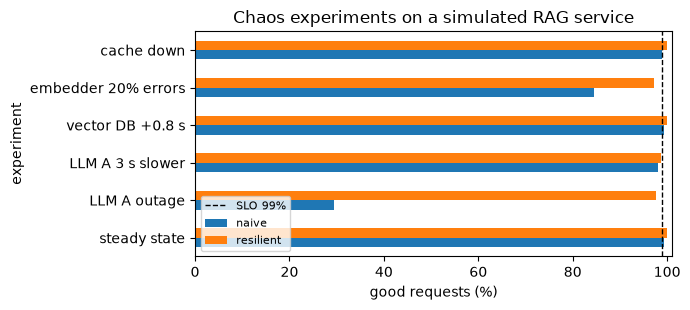

In [8]:
pivot = chaos.pivot(index="experiment", columns="design", values="good_%(SLI)").loc[list(EXPERIMENTS)]
ax = pivot.plot.barh(figsize=(7, 3.2))
ax.axvline(99, color="black", linestyle="--", linewidth=1, label="SLO 99%")
ax.set_xlabel("good requests (%)"); ax.set_xlim(0, 101); ax.set_title("Chaos experiments on a simulated RAG service")
ax.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

**Reading the results:**
- In the **steady state** both designs meet the SLO, so you would never notice the difference without an experiment.
- An **LLM A outage** destroys the naive design (every uncached request waits 30 s and fails). The resilient design falls back; the circuit breaker keeps most users from waiting for the timeout.
- **"LLM A 3 s slower"** is a quieter failure: nothing errors, so retries, fallbacks and the circuit breaker never trigger, and **both** designs miss the latency SLO. Slow-but-working dependencies need different tools: a tighter latency budget per call, hedged requests (send a second request to the fallback if the first is slow), or routing to a faster model. Latency faults are where real systems most often surprise people.
- **Embedder errors** show the value of a single retry, and **cache down** shows that the cache was hiding cost and latency (watch your token bill in this experiment too).

The next step in a real system is to run the same faults with Chaos Mesh, LitmusChaos or AWS FIS against staging, with a stop condition tied to the burn-rate alert from the [observability notebook](16_observability_hands_on.ipynb). Retry, backoff and circuit-breaker code itself is in [Computer networks for AI apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb).

```yaml
# Chaos Mesh: add 3 s latency to the LLM gateway pods in staging for 5 minutes (shown, not run)
apiVersion: chaos-mesh.org/v1alpha1
kind: NetworkChaos
metadata: {name: llm-gateway-delay, namespace: staging}
spec:
  action: delay
  mode: one
  selector: {namespaces: [staging], labelSelectors: {app: llm-gateway}}
  delay: {latency: "3s", jitter: "500ms"}
  duration: "5m"
```

## 6. Continuous profiling

**What it is:** a **profiler** measures where a program spends its time (or memory). **Continuous profiling** runs a low-overhead **sampling** profiler all the time in production: many times per second it records the current call stack of each process, and a backend aggregates the samples into **flame graphs** you can compare across versions and time ranges.

**Simple analogy:** instead of timing one lap with a stopwatch, you put a camera on the track that takes a photo every 10 ms all day. Where the runner appears most often is where time goes.

**How it works:**
1. An agent samples stacks (in-process SDK, or **eBPF** in the kernel, which needs no code changes).
2. Samples become "folded stacks" (`main;handle;retrieve;cosine 42`) and are sent to a backend.
3. You view flame graphs, filter by service, version, pod, or even by trace ID (to see why one slow span was slow).

| Tool | Notes (as of late 2026) |
|---|---|
| **Grafana Pyroscope** | open source, SDKs for many languages plus eBPF via Grafana Alloy |
| **Parca** (Polar Signals) | open source, eBPF-based agent, pprof format |
| **OpenTelemetry Profiles** | the fourth OTel signal; entered **public alpha in March 2026**, with an eBPF profiler donated by Elastic running in the Collector. Not yet for critical production use |
| Cloud profilers | Google Cloud Profiler, Amazon CodeGuru Profiler, Azure Application Insights Profiler, Datadog / other APM vendors |
| Local tools | `cProfile`, `py-spy` (sampling, attaches to a running process), `scalene`, `memray`, PyTorch profiler, NVIDIA Nsight for GPUs |

**When to use it:** when CPU cost or latency matters and the reason is not obvious from traces; for example tokenization, JSON parsing, pre/post-processing around a model call, or Python overhead in a retrieval step. **When not to:** if the time is spent waiting on the network or the GPU, a CPU profiler shows little; use traces (and GPU profilers) instead. Debugging and profiling basics are in [Debugging and profiling](../23_Software_Engineering/04_debugging_and_profiling.ipynb).

### 6.1 Runnable: cProfile a toy retrieval pipeline

In [9]:
DOCS = [" ".join(random.choice(["gpu", "token", "cache", "model", "vector", "latency", "cost", "agent", "prompt", "index"])
                 for _ in range(60)) for _ in range(400)]
VOCAB = {w: i for i, w in enumerate(sorted(set(" ".join(DOCS).split())))}

def tokenize_slow(text):
    out = []
    for ch_word in text.split(" "):          # deliberately clumsy: rebuilds strings char by char
        w = ""
        for ch in ch_word: w = w + ch.lower()
        out.append(VOCAB.get(w, 0))
    return out

def embed(tokens):
    v = np.zeros(len(VOCAB)); np.add.at(v, tokens, 1.0); return v / (np.linalg.norm(v) + 1e-9)

def search_slow(q, mat):
    scores = [float(sum(a * b for a, b in zip(q, row))) for row in mat]   # pure-Python dot products
    return int(np.argmax(scores))

def pipeline(queries, tokenize=tokenize_slow, search=search_slow):
    mat = np.array([embed(tokenize(d)) for d in DOCS])
    return [search(embed(tokenize(q)), mat) for q in queries]

QUERIES = DOCS[:40]
prof = cProfile.Profile(); prof.enable(); pipeline(QUERIES); prof.disable()
s = io.StringIO(); pstats.Stats(prof, stream=s).strip_dirs().sort_stats("cumulative").print_stats(8)
print("\n".join(l for l in s.getvalue().splitlines() if l.strip())[:2200])

         386135 function calls (386055 primitive calls) in 0.163 seconds
   Ordered by: cumulative time
   List reduced from 93 to 8 due to restriction <8>
   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    16000    0.028    0.000    0.073    0.000 {built-in method builtins.sum}
      440    0.035    0.000    0.064    0.000 2237494283.py:5(tokenize_slow)
   176000    0.046    0.000    0.046    0.000 2237494283.py:17(<genexpr>)
   134569    0.017    0.000    0.017    0.000 {method 'lower' of 'str' objects}
      440    0.003    0.000    0.012    0.000 2237494283.py:13(embed)
    26402    0.006    0.000    0.006    0.000 {method 'get' of 'dict' objects}
      440    0.005    0.000    0.005    0.000 {method 'at' of 'numpy.ufunc' objects}
      440    0.002    0.000    0.004    0.000 _linalg.py:2615(norm)


In [10]:
def tokenize_fast(text):
    return [VOCAB.get(w, 0) for w in text.lower().split(" ")]

def search_fast(q, mat):
    return int(np.argmax(mat @ q))           # one vectorised matrix-vector product

answers = {}
for name, kw in [("slow", {}), ("fast", {"tokenize": tokenize_fast, "search": search_fast})]:
    t0 = time.perf_counter(); answers[name] = pipeline(QUERIES, **kw); dt = time.perf_counter() - t0
    print(f"{name}: {dt * 1000:7.1f} ms")
print("same answers:", answers["slow"] == answers["fast"], "| lesson: measure first, then fix the widest bar")

slow:    75.9 ms
fast:     8.9 ms
same answers: True | lesson: measure first, then fix the widest bar


### 6.2 Runnable: how a sampling profiler builds a flame graph

A continuous profiler does not trace every call like `cProfile`; it **samples**. The tiny sampler below wakes up every 2 ms, looks at the main thread's current stack (`sys._current_frames()`), and counts "folded stacks". The counts are exactly what a flame graph draws: the wider the bar, the more samples.

In [11]:
def sample_stacks(target, interval=0.002):
    main_id = threading.get_ident(); counts = Counter(); stop = threading.Event()
    def sampler():
        while not stop.is_set():
            frame = sys._current_frames().get(main_id); stack = []
            while frame is not None:
                stack.append(frame.f_code.co_name); frame = frame.f_back
            names = [n for n in reversed(stack) if n in {"pipeline", "tokenize_slow", "embed", "search_slow", "<listcomp>", "<genexpr>"}]
            if names: counts[";".join(names)] += 1
            time.sleep(interval)
    th = threading.Thread(target=sampler, daemon=True); th.start()
    try: target()
    finally: stop.set(); th.join()
    return counts

old_switch = sys.getswitchinterval(); sys.setswitchinterval(0.0005)     # let the sampler thread run often
try:
    counts = sample_stacks(lambda: [pipeline(QUERIES[:25]) for _ in range(4)])
finally:
    sys.setswitchinterval(old_switch)
total = sum(counts.values())
print(f"{total} samples. Top folded stacks (this text format is what flame graph tools read):")
for stack, n in counts.most_common(6):
    print(f"{n:5d}  {100 * n / total:5.1f}%  {stack}")

78 samples. Top folded stacks (this text format is what flame graph tools read):
   36   46.2%  pipeline;search_slow;<genexpr>
   27   34.6%  pipeline;embed
   15   19.2%  pipeline;search_slow


**Compare with cProfile above:** cProfile says tokenization is a big share of the time, but our toy sampler barely sees it and over-counts `embed`. That is a real effect called **sampling bias**: this sampler is a Python thread, so it can only look when the main thread releases the GIL (global interpreter lock), which happens often inside NumPy calls such as those in `embed`. Production profilers such as `py-spy`, Pyroscope's eBPF mode or Parca read the stacks **from outside** the process, so they do not have this bias. The lesson for real work: know how your profiler samples, and cross-check with a second tool when a result looks surprising.

## 7. LLM-specific observability: tokens, cost and latency

**What it is:** normal observability (metrics, logs, traces; see [notebook 16](16_observability_hands_on.ipynb)) plus the things that only LLM apps have: **tokens in and out**, **cost per call**, **time to first token (TTFT)**, model and prompt **versions**, tool calls, retrieval results, and **quality** scores from evaluators or user feedback.

**Simple analogy:** a taxi meter on every request. You want to know not only that the trip finished, but how long it took, which route it used, and what it cost.

**OpenTelemetry GenAI semantic conventions** give these fields standard names, so any backend can read them. They are still marked **Development** (not stable) as of late 2026, so names can change; check the spec. Common span attributes:

| Attribute | Example |
|---|---|
| `gen_ai.operation.name` | `chat`, `embeddings`, `execute_tool`, `invoke_agent` |
| `gen_ai.provider.name` (older: `gen_ai.system`) | `openai`, `anthropic`, `aws.bedrock`, `azure.ai.inference` |
| `gen_ai.request.model` / `gen_ai.response.model` | requested vs actual model id |
| `gen_ai.usage.input_tokens` / `gen_ai.usage.output_tokens` | token counts |
| `gen_ai.request.temperature`, `gen_ai.request.max_tokens` | request settings |
| `gen_ai.response.finish_reasons` | `["stop"]`, `["length"]` |
| `error.type` | `timeout`, `429`, `content_filter` |

The span name is usually `"{operation} {model}"`, for example `chat gpt-4o-mini`. Prompt and completion **content** is opt-in (it may contain personal data); log it only with redaction and a retention policy.

| Tool | Type | Notes |
|---|---|---|
| **Langfuse** | open source (MIT core), self-host or cloud | traces, prompt management, evals; acquired by ClickHouse in January 2026, still open source |
| **Arize Phoenix** | open source | tracing and evals, OpenInference / OTel based |
| **LangSmith** | commercial (LangChain) | tracing, datasets, evals; works beyond LangChain |
| **OpenLLMetry** (Traceloop) | open source OTel instrumentation | sends GenAI spans to any OTel backend |
| **Helicone**, **W&B Weave**, **MLflow tracing** | proxy / SDK based | |
| APM vendors | Datadog LLM Observability, New Relic, Dynatrace, Grafana | LLM views on top of existing APM |
| Cloud | Amazon Bedrock AgentCore Observability, Microsoft Foundry observability, Gemini Enterprise Agent Platform observability | built into the managed agent platforms |

Hands-on tracing with LangChain and these tools is in [Advanced experiment tracking](10_advanced_experiment_tracking.ipynb) and [LLMOps](13_llmops.ipynb); token pricing, caching and batching maths is in [Tokens, cost, batch and caching](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb).

### 7.1 Runnable: a token / cost / latency dashboard from fake GenAI spans

In [12]:
PRICE = {   # ILLUSTRATIVE units per 1M tokens (input, output). Not real prices.
    "big-model":   (2.50, 10.00),
    "small-model": (0.15, 0.60),
    "embed-model": (0.02, 0.00),
}
features = {"support-chat": ("chat", "big-model"), "summarize": ("chat", "small-model"),
            "search": ("embeddings", "embed-model"), "agent": ("invoke_agent", "big-model")}
spans = []
t0 = datetime(2026, 11, 6, tzinfo=timezone.utc)
for i in range(4000):
    feat = random.choices(list(features), weights=[45, 25, 20, 10])[0]
    op, model = features[feat]
    day = random.randint(0, 6)
    inp = int(random.lognormvariate(math.log({"support-chat": 1800, "summarize": 3000, "search": 40, "agent": 9000}[feat]), 0.5))
    if feat == "agent" and day >= 5: inp *= 3                      # a prompt change on day 5 makes the agent loop longer
    out = 0 if op == "embeddings" else int(random.lognormvariate(math.log(350), 0.5))
    ttft = 0.0 if op == "embeddings" else random.lognormvariate(math.log(0.45 if model == "small-model" else 0.9), 0.4)
    dur = ttft + out * (0.006 if model == "small-model" else 0.015) + random.uniform(0.02, 0.1)
    err = random.choices([None, "timeout", "429", "content_filter"], weights=[970, 10, 15, 5])[0]
    spans.append({"name": f"{op} {model}", "gen_ai.operation.name": op, "gen_ai.provider.name": "example-provider",
                  "gen_ai.request.model": model, "gen_ai.usage.input_tokens": inp, "gen_ai.usage.output_tokens": out,
                  "app.feature": feat, "day": (t0 + timedelta(days=day)).date(), "ttft_s": ttft, "duration_s": dur,
                  "error.type": err})
sp = pd.DataFrame(spans)
pin = sp["gen_ai.request.model"].map(lambda m: PRICE[m][0]); pout = sp["gen_ai.request.model"].map(lambda m: PRICE[m][1])
sp["cost"] = (sp["gen_ai.usage.input_tokens"] * pin + sp["gen_ai.usage.output_tokens"] * pout) / 1e6
print(sp.iloc[0].to_dict())

{'name': 'chat small-model', 'gen_ai.operation.name': 'chat', 'gen_ai.provider.name': 'example-provider', 'gen_ai.request.model': 'small-model', 'gen_ai.usage.input_tokens': 3515, 'gen_ai.usage.output_tokens': 165, 'app.feature': 'summarize', 'day': datetime.date(2026, 11, 6), 'ttft_s': 0.6381736693496135, 'duration_s': 1.6838045846849297, 'error.type': nan, 'cost': 0.00062625}


              requests  in_tok_mean  out_tok_mean  ttft_p95_s  latency_p95_s  error_pct  cost_total  cost_per_1k_requests
app.feature                                                                                                              
support-chat      1801     2062.641       394.109       1.714         13.063      3.220      16.385                 9.098
agent              369    15618.634       404.951       1.765         12.666      0.813      15.902                43.096
summarize          987     3394.303       384.091       0.872          5.105      2.837       0.730                 0.740
search             843       45.057         0.000       0.000          0.097      3.084       0.001                 0.001


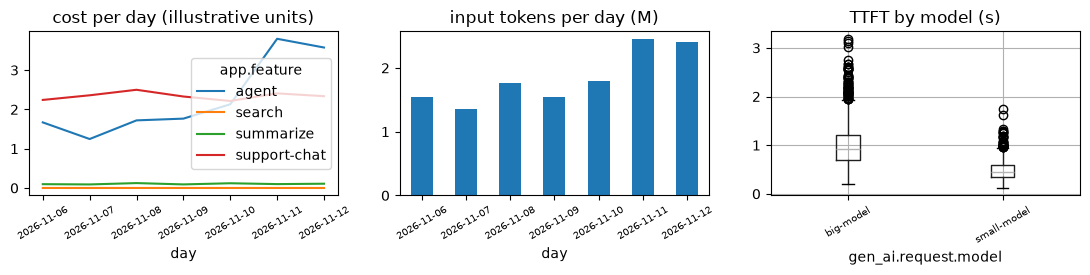

In [13]:
by_feature = sp.groupby("app.feature").agg(
    requests=("cost", "size"),
    in_tok_mean=("gen_ai.usage.input_tokens", "mean"),
    out_tok_mean=("gen_ai.usage.output_tokens", "mean"),
    ttft_p95_s=("ttft_s", lambda s: s.quantile(0.95)),
    latency_p95_s=("duration_s", lambda s: s.quantile(0.95)),
    error_pct=("error.type", lambda s: 100 * s.notna().mean()),
    cost_total=("cost", "sum"))
by_feature["cost_per_1k_requests"] = 1000 * by_feature.cost_total / by_feature.requests
print(by_feature.round(3).sort_values("cost_total", ascending=False).to_string())

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
sp.groupby(["day", "app.feature"]).cost.sum().unstack().plot(ax=axes[0], title="cost per day (illustrative units)")
sp.groupby("day")["gen_ai.usage.input_tokens"].sum().div(1e6).plot.bar(ax=axes[1], title="input tokens per day (M)")
sp[sp["gen_ai.operation.name"] != "embeddings"].boxplot(column="ttft_s", by="gen_ai.request.model", ax=axes[2])
axes[2].set_title("TTFT by model (s)"); fig.suptitle("")
for a in axes: a.tick_params(axis="x", labelsize=7, rotation=30)
plt.tight_layout(); plt.show()

In [14]:
# A simple alert rule: cost per request for a feature jumps > 50% versus its previous-days median.
daily = sp.groupby(["app.feature", "day"]).agg(cost=("cost", "sum"), n=("cost", "size"))
daily["cost_per_req"] = daily.cost / daily.n
for feat, g in daily.groupby(level=0):
    g = g.droplevel(0)
    baseline = g.cost_per_req.iloc[:5].median()
    for day, v in g.cost_per_req.iloc[5:].items():
        if v > 1.5 * baseline:
            print(f"ALERT {feat}: cost/request on {day} = {v:.4f}, {v / baseline:.1f}x the baseline {baseline:.4f}")
print("(the agent's prompt change on day 5 tripled input tokens: the dashboard and the alert both catch it)")

ALERT agent: cost/request on 2026-11-11 = 0.0825, 2.7x the baseline 0.0309
ALERT agent: cost/request on 2026-11-12 = 0.0831, 2.7x the baseline 0.0309
(the agent's prompt change on day 5 tripled input tokens: the dashboard and the alert both catch it)


# Part B: Security and compliance for AI deployments

Application-level security (OWASP, JWT, prompt injection, supply chain) is in [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb) and [LLM security](../08_LLM/16_llm_security.ipynb); the threat landscape is in [AI and cybersecurity 01](../27_AI_and_Cybersecurity/01_ai_native_threat_landscape.ipynb). This part is about the **platform**: who and what may reach the model, where keys live, how data is encrypted, and how you prove it.

## 8. Zero trust, identity-based access and network segmentation

**What it is:** **zero trust** is a security model that removes "trusted inside network" thinking. Every request is checked, every time, based on **who** (identity), **what** (device or workload health), **which resource** and **context**, no matter where it comes from. NIST SP 800-207 describes it with a **policy decision point (PDP)** that decides and a **policy enforcement point (PEP)** that blocks or allows. Google's BeyondCorp is a well-known early example.

**Simple analogy:** an old castle trusts anyone who got past the moat. A zero-trust office checks your badge at **every door**, and your badge only opens the rooms you need today.

**The NIST SP 800-207 tenets, in plain words:**
1. Everything (data, services, devices, AI agents) is a resource to protect.
2. All communication is secured, whatever the network location.
3. Access is granted per session, with least privilege.
4. Access depends on dynamic policy: identity, device or workload state, behaviour, context.
5. The health and security posture of all assets is monitored.
6. Authentication and authorisation are dynamic and enforced before access.
7. Collect telemetry and use it to improve the policy.

**Identity-based access for AI workloads:**
- Workloads use **short-lived identities**, not static keys: AWS IAM roles (EKS Pod Identity, IRSA), Azure **managed identities** and workload identity federation, Google Cloud **service accounts** with Workload Identity Federation. CI pipelines use **OIDC federation** to the cloud instead of stored keys.
- **AI agents are identities too:** each agent gets its own agent identity, scoped tokens for each tool (for remote MCP servers, OAuth-based MCP authorization), on-behalf-of delegation when it acts for a user, and every action is logged (see [agent security](../10_Agents/08_agent_security.ipynb)).
- Humans use SSO with phishing-resistant MFA; admin rights are **just-in-time** and time-limited.

**Network segmentation:** split the network so that a compromise of one part does not reach everything.

```mermaid
flowchart TB
    I[Internet] --> W[WAF + load balancer: public subnet]
    subgraph VPC[VPC / VNet]
      W --> A[RAG API: private app subnet]
      A --> D[(vector DB, Postgres: private data subnet)]
      A --> G[GPU model servers: private subnet]
      A --> N[NAT gateway / egress proxy] --> P[LLM provider APIs]
      A -. private endpoint .-> S[(object storage, secrets manager, managed LLM)]
    end
    B[Admins via SSO + session manager] -. no public SSH .-> A
```

- **Public subnet** only for load balancers; app, data and GPU nodes in **private subnets** with no public IPs.
- Reach cloud services through **private endpoints** (AWS PrivateLink / VPC endpoints, Azure Private Link, Google Private Service Connect), so traffic to storage, secrets and managed model APIs (Bedrock, Azure OpenAI in Foundry, Agent Platform) never crosses the internet.
- Control **egress**: an allow-list proxy stops a compromised app (or a prompt-injected agent) from sending data anywhere.
- Inside Kubernetes, **NetworkPolicies** (Calico, Cilium) and **mTLS** in a service mesh segment pod-to-pod traffic.
- Avoid public SSH and **bastion hosts** where you can; use session managers tied to identity (see the [Linux notebook](../23_Software_Engineering/13_linux_shell_and_networking_for_ai_engineers.ipynb)).

### 8.1 Runnable: a tiny policy decision point

In [15]:
POLICIES = [  # evaluated in order; first match wins; default deny
    {"id": "P1", "effect": "deny",  "if": lambda r: r["device_ok"] is False, "why": "unhealthy device or workload"},
    {"id": "P2", "effect": "allow", "if": lambda r: r["subject_type"] == "workload" and r["subject"] == "rag-api"
                                         and r["resource"] == "vector-db" and r["action"] == "read", "why": "rag-api reads vectors"},
    {"id": "P3", "effect": "allow", "if": lambda r: r["subject_type"] == "agent" and r["resource"] == "crm"
                                         and r["action"] == "read" and r["token_age_min"] <= 15, "why": "agent read with fresh token"},
    {"id": "P4", "effect": "allow", "if": lambda r: r["subject_type"] == "human" and r["mfa"] and r["role"] == "ml-admin"
                                         and r["resource"] == "model-registry" and r["jit_approved"], "why": "JIT admin with MFA"},
]
def pdp(req):
    for p in POLICIES:
        if p["if"](req):
            return p["effect"], p["id"], p["why"]
    return "deny", "default", "no policy matched"

base = dict(device_ok=True, mfa=False, role=None, jit_approved=False, token_age_min=0)
requests_ = [
    dict(base, subject_type="workload", subject="rag-api", resource="vector-db", action="read"),
    dict(base, subject_type="workload", subject="rag-api", resource="vector-db", action="delete"),
    dict(base, subject_type="agent", subject="support-agent", resource="crm", action="read", token_age_min=5),
    dict(base, subject_type="agent", subject="support-agent", resource="crm", action="read", token_age_min=90),
    dict(base, subject_type="agent", subject="support-agent", resource="crm", action="write", token_age_min=5),
    dict(base, subject_type="human", subject="ana", resource="model-registry", action="write", mfa=True, role="ml-admin", jit_approved=True),
    dict(base, subject_type="human", subject="ana", resource="model-registry", action="write", mfa=True, role="ml-admin", device_ok=False),
]
for r in requests_:
    eff, pid, why = pdp(r)
    print(f"{r['subject']:<14} {r['action']:<6} {r['resource']:<15} -> {eff:<5} [{pid}] {why}")

rag-api        read   vector-db       -> allow [P2] rag-api reads vectors
rag-api        delete vector-db       -> deny  [default] no policy matched
support-agent  read   crm             -> allow [P3] agent read with fresh token
support-agent  read   crm             -> deny  [default] no policy matched
support-agent  write  crm             -> deny  [default] no policy matched
ana            write  model-registry  -> allow [P4] JIT admin with MFA
ana            write  model-registry  -> deny  [P1] unhealthy device or workload


### 8.2 Runnable: what can the internet reach? Flat network vs segmented

We describe allowed flows as a graph and walk it from `internet`. In a flat network, one compromised entry point reaches the database; in a segmented one, every path goes through the API, which is where we put authentication, rate limits and logging.

In [16]:
def reachable(edges, start="internet"):
    seen, todo, paths = {start}, [start], {start: [start]}
    while todo:
        n = todo.pop()
        for a, b in edges:
            if a == n and b not in seen:
                seen.add(b); todo.append(b); paths[b] = paths[n] + [b]
    return paths

flat = [("internet", "jupyter"), ("internet", "api"), ("internet", "ssh-vm"), ("jupyter", "vector-db"),
        ("api", "vector-db"), ("ssh-vm", "postgres"), ("api", "gpu-model"), ("jupyter", "gpu-model")]
segmented = [("internet", "waf-lb"), ("waf-lb", "api"), ("api", "vector-db"), ("api", "gpu-model"),
             ("api", "egress-proxy"), ("egress-proxy", "llm-provider")]
for name, edges in [("flat", flat), ("segmented", segmented)]:
    paths = reachable(edges)
    direct = sorted(b for a, b in edges if a == "internet")
    print(f"{name:<10} directly exposed: {direct}")
    for target in ("vector-db", "postgres"):
        if target in paths: print(f"{'':<10} path to {target}: {' -> '.join(paths[target])}")

flat       directly exposed: ['api', 'jupyter', 'ssh-vm']
           path to vector-db: internet -> api -> vector-db
           path to postgres: internet -> ssh-vm -> postgres
segmented  directly exposed: ['waf-lb']
           path to vector-db: internet -> waf-lb -> api -> vector-db


## 9. Secrets and API-key management and rotation

**What it is:** a **secret** is anything that grants access: LLM provider keys, database passwords, signing keys, OAuth client secrets. **Secrets management** means storing them in one protected service, giving each workload only what it needs, logging every read, and **rotating** them (replacing with new values) regularly and immediately after a leak.

**Simple analogy:** office keys kept in a locked key cabinet with a sign-out sheet, and the locks changed every few months, instead of copies taped under desks.

| Tool | Notes |
|---|---|
| AWS Secrets Manager, AWS Systems Manager Parameter Store | versioned secrets with staging labels (`AWSCURRENT`, `AWSPENDING`, `AWSPREVIOUS`); built-in rotation via Lambda for databases |
| Azure Key Vault | secrets, keys, certificates; rotation policies; access via managed identity |
| Google Cloud Secret Manager | versioned secrets, rotation schedules that notify via Pub/Sub |
| HashiCorp Vault / OpenBao | dynamic secrets (a fresh database user per app with a lease), PKI, multi-cloud |
| Kubernetes: External Secrets Operator, Secrets Store CSI Driver, Sealed Secrets, SOPS | sync cloud secrets into pods, or store encrypted secrets in Git |

**Rotation without downtime** needs an **overlap**:
1. Create a new key while the old one still works (most LLM providers allow several active keys per project).
2. Store it as the new current version in the secret manager.
3. Wait until every client has picked it up (longer than the clients' cache time), or push a reload.
4. Revoke the old key and watch for errors from anything still using it.

Better still, avoid long-lived keys entirely: workload identity to the cloud provider's model APIs (Bedrock, Foundry, Agent Platform accept IAM / Entra / Google identities), and short-lived tokens issued by a gateway for third-party APIs. Detecting leaked keys in code and logs is covered in [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb).

### 9.1 Runnable: rotation simulation

Twenty API replicas each cache the provider key for 5 minutes and refresh at random times. We rotate at minute 20 with three strategies and count failed calls.

In [17]:
def simulate_rotation(strategy, n_clients=20, cache_ttl=300, horizon=3600, rotate_at=1200, overlap=600, seed=SEED):
    r = random.Random(seed)
    store = {"current": "key-v1"}; valid = {"key-v1"}
    clients = [{"key": "key-v1", "next_refresh": r.uniform(0, cache_ttl)} for _ in range(n_clients)]
    fails = Counter(); revoke_at = None
    for t in range(0, horizon, 5):                                  # every 5 s each client makes a call
        if t == rotate_at:
            store["current"] = "key-v2"; valid.add("key-v2")
            if strategy == "immediate revoke":
                valid.discard("key-v1")
            elif strategy == "overlap then revoke":
                revoke_at = t + overlap                            # wait longer than the cache TTL
            elif strategy == "emergency revoke + push reload":
                valid.discard("key-v1")
                for c in clients: c["next_refresh"] = t + r.uniform(5, 30)   # reload signal reaches pods in 5-30 s
        if revoke_at is not None and t == revoke_at:
            valid.discard("key-v1")
        for c in clients:
            if t >= c["next_refresh"]:
                c["key"] = store["current"]; c["next_refresh"] = t + cache_ttl
            if c["key"] not in valid:
                fails[t // 60] += 1
    return sum(fails.values()), fails

rows = []
for s in ["immediate revoke", "overlap then revoke", "emergency revoke + push reload"]:
    total, per_min = simulate_rotation(s)
    rows.append({"strategy": s, "failed_calls": total, "minutes_with_failures": len(per_min)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nUse overlap for scheduled rotation; for a LEAKED key, revoke at once and push a reload (a short burst of errors is the price).")

                      strategy  failed_calls  minutes_with_failures
              immediate revoke           477                      5
           overlap then revoke             0                      0
emergency revoke + push reload            89                      1

Use overlap for scheduled rotation; for a LEAKED key, revoke at once and push a reload (a short burst of errors is the price).


## 10. Encryption at rest, in transit and in use

**What it is:**
- **In transit:** TLS between clients and the edge, and between services (**mTLS** inside a mesh), including calls to model providers.
- **At rest:** disks, object storage, databases, vector indexes, backups and **model weights** encrypted with keys in a **KMS** (AWS KMS, Azure Key Vault, Google Cloud KMS). **CMK** (customer-managed keys) or BYOK lets you control and revoke the key; some regulated customers require it.
- **In use:** **confidential computing** keeps data encrypted in memory inside a hardware-protected enclave (AMD SEV-SNP, Intel TDX, and confidential GPU modes on NVIDIA H100 and newer). Used for sensitive inference and multi-party data.

**Envelope encryption** is how KMS-based encryption works at scale: each object is encrypted with its own **data key (DEK)**; the DEK is encrypted ("wrapped") by a **key-encryption key (KEK)** that never leaves the KMS. To rotate the KEK, you only re-wrap the small DEKs, not terabytes of data.

**Simple analogy:** each box in a warehouse has its own padlock; the padlock keys live in one safe. Changing the safe's combination does not require changing every padlock.

The toy below shows the mechanics. **It is NOT real cryptography** (it builds a keystream from SHA-256 for illustration only). In real code use your cloud KMS SDK or a vetted library such as `cryptography` (AES-GCM).

In [18]:
def toy_stream_xor(key: bytes, nonce: bytes, data: bytes) -> bytes:
    """TOY ONLY - not secure. XOR data with a SHA-256-derived keystream."""
    stream = b"".join(hashlib.sha256(key + nonce + i.to_bytes(4, "big")).digest() for i in range(len(data) // 32 + 1))
    return bytes(a ^ b for a, b in zip(data, stream))

class ToyKMS:
    def __init__(self): self.keks = {"kek-v1": secrets.token_bytes(32)}; self.current = "kek-v1"
    def rotate(self): v = f"kek-v{len(self.keks) + 1}"; self.keks[v] = secrets.token_bytes(32); self.current = v
    def wrap(self, dek): n = secrets.token_bytes(12); return (self.current, n, toy_stream_xor(self.keks[self.current], n, dek))
    def unwrap(self, w): ver, n, c = w; return toy_stream_xor(self.keks[ver], n, c)

kms = ToyKMS(); store = {}
for name, blob in {"model.safetensors": b"weights" * 2000, "rag-index.bin": b"vectors" * 3000}.items():
    dek, nonce = secrets.token_bytes(32), secrets.token_bytes(12)
    store[name] = {"nonce": nonce, "cipher": toy_stream_xor(dek, nonce, blob), "wrapped_dek": kms.wrap(dek)}
data_bytes = sum(len(o["cipher"]) for o in store.values())

kms.rotate()                                                    # rotate the KEK
for o in store.values():                                        # re-wrap only the 32-byte DEKs
    o["wrapped_dek"] = kms.wrap(kms.unwrap(o["wrapped_dek"]))
o = store["model.safetensors"]
plain = toy_stream_xor(kms.unwrap(o["wrapped_dek"]), o["nonce"], o["cipher"])
print("decrypts after KEK rotation:", plain[:14], "...")
print(f"bytes re-encrypted for rotation: {32 * len(store)} (DEKs) instead of {data_bytes} (all data)")

decrypts after KEK rotation: b'weightsweights' ...
bytes re-encrypted for rotation: 64 (DEKs) instead of 35000 (all data)


## 11. Cloud security posture: CSPM, CNAPP and friends

**What it is:** cloud accounts drift into risky settings: a public bucket of training data, a GPU VM with SSH open to the world, an unencrypted disk, an over-privileged role. **Posture management** tools continuously scan cloud configuration (through cloud APIs) against rules and benchmarks and report findings.

**Simple analogy:** a building inspector who walks every floor every day with a checklist, instead of once a year.

| Acronym | Means | Looks at |
|---|---|---|
| **CSPM** | Cloud Security Posture Management | cloud configuration vs benchmarks (CIS, provider best practices) |
| **CWPP** | Cloud Workload Protection Platform | VMs, containers, serverless at runtime (vulnerabilities, malware) |
| **CIEM** | Cloud Infrastructure Entitlement Management | who can do what; unused or excessive permissions |
| **DSPM** | Data Security Posture Management | where sensitive data lives and who can reach it |
| **KSPM** | Kubernetes Security Posture Management | cluster and workload configuration |
| **AI-SPM** | AI Security Posture Management | model endpoints, AI services, training data, agent permissions |
| **CNAPP** | Cloud-Native Application Protection Platform | one platform combining the above plus code / IaC scanning and runtime detection |

**Products (named generally, as of late 2026):** Wiz (acquired by Google, deal closed March 2026; still multi-cloud), Palo Alto Networks Cortex Cloud (formerly Prisma Cloud), Microsoft Defender for Cloud, AWS Security Hub (the original service is now Security Hub CSPM; the new Security Hub correlates it with GuardDuty, Inspector and Macie), Google Security Command Center, and others (CrowdStrike, SentinelOne, Orca, Sysdig, Aqua). **Open source:** Prowler, Checkov and Trivy (IaC and image scanning), kube-bench, Kubescape, Falco (runtime detection).

**When to use:** from the first production account. Start with the free native tools of your cloud and IaC scanning in CI (see [CI/CD](../20_Git_and_DevOps/03_github_actions_cicd.ipynb)); add a CNAPP when you run several accounts or clouds.

### 11.1 Runnable: a mini posture scanner

In [19]:
INVENTORY = [  # a made-up cloud inventory, like what a CSPM pulls from cloud APIs
    {"id": "s3://acme-train-data", "type": "bucket", "public": True, "encrypted": True, "tags": {"team": "ml"}},
    {"id": "s3://acme-logs", "type": "bucket", "public": False, "encrypted": False, "tags": {"team": "platform", "env": "prod"}},
    {"id": "vm-gpu-01", "type": "vm", "public_ip": True, "ingress": [("0.0.0.0/0", 22), ("0.0.0.0/0", 8888)],
     "disk_encrypted": True, "tags": {"team": "research"}},
    {"id": "vm-api-01", "type": "vm", "public_ip": False, "ingress": [("10.0.0.0/16", 8000)], "disk_encrypted": True,
     "tags": {"team": "ml", "env": "prod", "cost_center": "cc-42"}},
    {"id": "endpoint-llm-prod", "type": "model_endpoint", "auth": "none", "network": "public", "logging": False,
     "tags": {"team": "ml", "env": "prod"}},
    {"id": "role-ci-deployer", "type": "iam_role", "policies": ["AdministratorAccess"], "last_used_days": 2, "tags": {}},
    {"id": "user-old-intern", "type": "iam_user", "access_keys": 1, "key_age_days": 400, "last_used_days": 180, "tags": {}},
]
RULES = [  # (id, severity, applies-to type, check -> True means FINDING, message, framework hints)
    ("CS-01", "critical", "bucket", lambda r: r["public"], "bucket is public", "CIS storage / SOC 2 CC6.1 / ISO A.8.3"),
    ("CS-02", "high", "bucket", lambda r: not r["encrypted"], "bucket not encrypted at rest", "SOC 2 CC6.1 / ISO A.8.24"),
    ("CS-03", "critical", "vm", lambda r: any(c == "0.0.0.0/0" and p in (22, 3389) for c, p in r["ingress"]), "SSH/RDP open to the internet", "CIS network"),
    ("CS-04", "critical", "vm", lambda r: any(c == "0.0.0.0/0" and p in (8888, 8000, 11434) for c, p in r["ingress"]), "notebook / model port open to the internet", "AI-SPM"),
    ("CS-05", "critical", "model_endpoint", lambda r: r["auth"] == "none", "model endpoint without authentication", "AI-SPM / OWASP LLM10"),
    ("CS-06", "medium", "model_endpoint", lambda r: not r["logging"], "no request logging on model endpoint", "SOC 2 CC7.2 / ISO A.8.15"),
    ("CS-07", "high", "iam_role", lambda r: "AdministratorAccess" in r["policies"], "admin rights on a CI role", "CIEM / least privilege"),
    ("CS-08", "high", "iam_user", lambda r: r["access_keys"] and r["key_age_days"] > 90, "long-lived access key older than 90 days", "CIS IAM"),
    ("CS-09", "medium", "iam_user", lambda r: r["last_used_days"] > 90, "inactive user still enabled", "SOC 2 CC6.2"),
    ("CS-10", "low", "*", lambda r: not {"team", "env"} <= set(r["tags"]), "missing required tags (team, env)", "FinOps / asset inventory"),
]
findings = [{"resource": r["id"], "rule": rid, "severity": sev, "finding": msg, "maps_to": fw}
            for r in INVENTORY for rid, sev, typ, check, msg, fw in RULES if typ in ("*", r["type"]) and check(r)]
fd = pd.DataFrame(findings)
order = {"critical": 0, "high": 1, "medium": 2, "low": 3}
fd = fd.sort_values(by="severity", key=lambda s: s.map(order))
print(fd.to_string(index=False))
print("\nfindings by severity:", fd.severity.value_counts().reindex(order).fillna(0).astype(int).to_dict())

            resource  rule severity                                    finding                               maps_to
s3://acme-train-data CS-01 critical                           bucket is public CIS storage / SOC 2 CC6.1 / ISO A.8.3
           vm-gpu-01 CS-03 critical               SSH/RDP open to the internet                           CIS network
   endpoint-llm-prod CS-05 critical      model endpoint without authentication                  AI-SPM / OWASP LLM10
           vm-gpu-01 CS-04 critical notebook / model port open to the internet                                AI-SPM
      s3://acme-logs CS-02     high               bucket not encrypted at rest              SOC 2 CC6.1 / ISO A.8.24
    role-ci-deployer CS-07     high                  admin rights on a CI role                CIEM / least privilege
     user-old-intern CS-08     high   long-lived access key older than 90 days                               CIS IAM
   endpoint-llm-prod CS-06   medium       no request logging on 

## 12. Compliance in plain words, and audit evidence

**Not legal advice.** Laws and standards change and depend on your country, sector and contracts. This section is a map so you know the words and what engineers typically build; your legal, privacy and compliance teams decide what applies.

**What it is:** **compliance** means showing that you follow a set of rules: a law (GDPR, HIPAA, the EU AI Act) or a standard customers ask for (SOC 2, ISO/IEC 27001, ISO/IEC 42001). In practice it means having **controls** (things you do, like access reviews, encryption, change approval) and **evidence** that they work.

**Simple analogy:** a restaurant hygiene inspection. You need clean kitchens every day (controls) and the cleaning log to prove it (evidence).

| Framework | What it is | Who asks for it | What engineers usually build |
|---|---|---|---|
| **SOC 2** (AICPA) | an independent auditor's **attestation report** on your controls, against the Trust Services Criteria: security, availability, processing integrity, confidentiality, privacy. **Type I** = designed correctly at a point in time; **Type II** = worked over a period (often 6-12 months) | B2B customers, mostly in North America | access reviews, MFA, logging, change management in CI/CD, backups, incident response, vendor reviews |
| **ISO/IEC 27001:2022** | a **certifiable** information security management system (ISMS): risk assessment plus Annex A controls (93 controls in 4 themes: organisational, people, physical, technological) | customers worldwide, public sector | same family of controls as SOC 2, plus a formal risk register and statement of applicability |
| **ISO/IEC 42001:2023** | a **certifiable AI management system**: AI policy, risk and impact assessment, data and model lifecycle controls, transparency, supplier management | customers buying AI products; a structured way to show responsible-AI practice | model and data inventory, impact assessments, eval and monitoring evidence, human oversight records |
| **HIPAA** (US) | law protecting health information (**PHI**) | US healthcare providers, insurers and their vendors | a **Business Associate Agreement (BAA)** with every vendor that touches PHI (cloud, LLM API), encryption, access logs, minimum necessary data |
| **GDPR** (EU/EEA, plus the UK GDPR) | law on personal data | anyone processing EU/UK personal data | lawful basis, data minimisation, retention limits, data subject rights (access, deletion), DPIAs for risky processing, data processing agreements, **data residency** and transfer rules |
| **EU AI Act** | EU law on AI systems by risk level | providers and deployers of AI in the EU | AI-system inventory and risk classification, transparency notices (chatbots, AI-generated content), and for high-risk systems: risk management, data governance, logging, human oversight, robustness and cybersecurity |
| **PCI DSS**, **FedRAMP** | card-payment data; US federal cloud authorisation | payments; US government buyers | network segmentation of card data; strict control baselines |

**EU AI Act timing (as of late 2026, check the official text):** prohibited practices apply since February 2025 and general-purpose AI model rules since August 2025. The 2026 "Digital Omnibus" amendment (Regulation (EU) 2026/1744) postponed the **high-risk** obligations: to 2 December 2027 for stand-alone (Annex III) systems and 2 August 2028 for AI inside regulated products (Annex I). Transparency duties under Article 50 were not postponed. See [AI regulation and compliance](../19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb) for risk classes and obligations.

**Shared responsibility:** the cloud provider (and the LLM provider) is responsible for the security **of** its platform; you are responsible for security **in** it: your configuration, identities, data and application. Their SOC 2 / ISO reports (AWS Artifact, Microsoft Service Trust Portal, Google Compliance Reports Manager) cover their part, not yours.

**Audit logs** are the raw material: cloud control-plane logs (AWS CloudTrail, Azure Activity Log, Google Cloud Audit Logs), identity-provider sign-ins, Kubernetes audit logs, and application logs of who called which model or tool with which data. Send them to a separate, locked-down account so an attacker who gets into production cannot erase them.

**Audit evidence collection:** auditors want proof that a control ran, when, and that the proof was not edited afterwards. Collect it **automatically**: scanner results, access-review exports, CI/CD approval logs, backup-restore test logs, training records. Store it with timestamps and hashes, in write-once storage (for example S3 Object Lock or immutable Azure Blob storage). Compliance automation platforms (Vanta, Drata, Secureframe and similar) and cloud services (AWS Audit Manager, Microsoft Purview Compliance Manager, Google Cloud Compliance Manager / Audit Manager) do this at scale.

### 12.1 Runnable: an evidence pack with a hash chain

In [20]:
collected_at = datetime(2026, 11, 13, 9, 0, tzinfo=timezone.utc)
CONTROLS = [  # control id (generic), description, evidence source, pass rule
    ("AC-01", "No public storage buckets",            "posture scan",  lambda: not any(fd.rule == "CS-01")),
    ("AC-02", "No long-lived keys older than 90 days", "posture scan",  lambda: not any(fd.rule == "CS-08")),
    ("AC-03", "Quarterly access review completed",     "IdP export",    lambda: True),
    ("CM-01", "Prod deploys need an approved PR",      "CI/CD log",     lambda: True),
    ("LG-01", "Model endpoints log requests",          "posture scan",  lambda: not any(fd.rule == "CS-06")),
    ("AI-01", "Every prod model has an eval report",   "model registry", lambda: False),
]
prev_hash, pack = "0" * 64, []
for cid, desc, source, rule in CONTROLS:
    record = {"control": cid, "description": desc, "source": source, "status": "pass" if rule() else "FAIL",
              "collected_at": collected_at.isoformat(), "prev_hash": prev_hash}
    record["hash"] = hashlib.sha256(json.dumps(record, sort_keys=True).encode()).hexdigest()
    prev_hash = record["hash"]; pack.append(record)
ev = pd.DataFrame(pack)
ev["hash"] = ev["hash"].str[:12] + "..."; ev["prev_hash"] = ev["prev_hash"].str[:12] + "..."
print(ev[["control", "description", "source", "status", "prev_hash", "hash"]].to_string(index=False))

def verify(pack):
    prev = "0" * 64
    for rec in pack:
        body = {k: v for k, v in rec.items() if k != "hash"}
        if body["prev_hash"] != prev or hashlib.sha256(json.dumps(body, sort_keys=True).encode()).hexdigest() != rec["hash"]:
            return f"tampering detected at {rec['control']}"
        prev = rec["hash"]
    return "chain intact"
print("\nverify original:", verify(pack))
pack[2]["status"] = "pass (edited later)"
print("verify after editing one record:", verify(pack))

control                           description         source status       prev_hash            hash
  AC-01             No public storage buckets   posture scan   FAIL 000000000000... 016493fb1aa3...
  AC-02 No long-lived keys older than 90 days   posture scan   FAIL 016493fb1aa3... ad25d7664b79...
  AC-03     Quarterly access review completed     IdP export   pass ad25d7664b79... 0b2c1644c4bf...
  CM-01      Prod deploys need an approved PR      CI/CD log   pass 0b2c1644c4bf... 017b0e3029bb...
  LG-01          Model endpoints log requests   posture scan   FAIL 017b0e3029bb... a23bb510aa5f...
  AI-01   Every prod model has an eval report model registry   FAIL a23bb510aa5f... 35b747e69a29...

verify original: chain intact
verify after editing one record: tampering detected at AC-03


# Part C: FinOps for AI systems

## 13. FinOps in one page

**What it is:** **FinOps** (cloud financial operations) is the practice of engineering, finance and product teams working together so that every unit of cloud and AI spend buys business value. The FinOps Foundation's framework describes three phases that repeat in a loop:

| Phase | Question | Typical work |
|---|---|---|
| **Inform** | Where does the money go, and who owns it? | billing exports, **tags/labels**, allocation, **showback** / chargeback, budgets, forecasts |
| **Optimize** | How can we get the same value for less? | rightsizing, commitments, spot, scaling to zero, model routing, caching, storage lifecycle policies (move old checkpoints and logs to cheaper storage tiers), cutting data transfer costs (keep GPUs, data and vector DBs in the same region; watch NAT and cross-region egress fees) |
| **Operate** | How do we keep it that way? | policies (tags required, budgets), automation (off-hours shutdown), reviews, KPIs like cost per unit |

The 2025 framework update added **Scopes**, so the same practice covers public cloud, SaaS, data centres and, increasingly, **AI spend** (GPU, model APIs, tokens). Billing data from different providers is being standardised as **FOCUS** (FinOps Open Cost and Usage Specification; version 1.4 was ratified in June 2026), with columns such as `BilledCost`, `EffectiveCost`, `ServiceCategory`, `ResourceId`, `ChargePeriodStart` and `Tags`. AWS, Azure, Google Cloud and Oracle offer FOCUS-format exports.

**Simple analogy:** a household budget where every bill is labelled with whose it is, compared each month, and where the heating switches off automatically when nobody is home.

The [cloud cost notebooks](../18_Cloud/04_cloud_cost_optimization.ipynb) cover cost drivers and [architecture cost planning](../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb) (break-even, TCO, autoscaling). Here we do the day-to-day FinOps work on a fake billing export.

## 14. Cost allocation tags and a showback report

**What it is:** **tags** (AWS, Azure) or **labels** (Google Cloud, Kubernetes) are key-value pairs on resources, like `team=search` or `env=prod`. Billing exports carry them, so you can group cost by owner. A **tag policy** says which keys are required and which values are allowed. **Showback** shows each team its costs; **chargeback** actually bills them internally.

**How it works:** decide the required keys (for example `team`, `env`, `app`, `cost_center`), enforce them at creation time (AWS Organizations tag policies and SCPs, Azure Policy, Google Cloud organisation policies, IaC checks in CI), and activate the tags as **cost allocation tags** in the billing console. Untaggable or shared costs (networking, support, a shared observability stack) are **split** by a rule, for example proportional to each team's direct cost.

In [21]:
SERVICES = [  # (service name, FOCUS-like ServiceCategory, resource prefix, daily cost range) - all made up
    ("GPU VMs", "Compute", "vm-gpu", (40, 120)), ("Kubernetes nodes", "Compute", "node", (10, 30)),
    ("Object storage", "Storage", "bucket", (1, 6)), ("Managed LLM API", "AI and Machine Learning", "llm", (20, 80)),
    ("Vector DB", "Databases", "vdb", (5, 15)), ("NAT / data transfer", "Networking", "nat", (3, 9)),
    ("Observability", "Management and Governance", "obs", (4, 8)),
]
TEAMS = ["search", "support-ai", "research", "platform"]
resources = []
for i in range(40):
    svc, cat, prefix, (lo, hi) = random.choice(SERVICES)
    team = random.choice(TEAMS)
    tags = {"team": team, "env": random.choice(["prod", "prod", "dev", "staging"]), "app": f"{team}-app"}
    roll = random.random()
    if roll < 0.15: tags = {}                                   # untagged
    elif roll < 0.25: tags.pop("env")                           # missing a required key
    elif roll < 0.30: tags["team"] = team.upper()               # wrong value (case)
    if prefix in ("nat", "obs"): tags = {"env": "prod", "shared": "true"}   # shared infrastructure
    resources.append((f"{prefix}-{i:02d}", svc, cat, lo, hi, tags))

days = pd.date_range("2026-10-01", "2026-10-31", freq="D")
bill = pd.DataFrame([{"ChargePeriodStart": d, "ResourceId": rid, "ServiceName": svc, "ServiceCategory": cat,
                      "BilledCost": round(random.uniform(lo, hi), 2), "Tags": json.dumps(tags)}
                     for d in days for rid, svc, cat, lo, hi, tags in resources])
bill["EffectiveCost"] = bill["BilledCost"]                       # (after discounts; same here for simplicity)
print(bill.head(3).to_string(index=False)); print("rows:", len(bill), "| total:", round(bill.EffectiveCost.sum(), 2), "units")

ChargePeriodStart ResourceId     ServiceName         ServiceCategory  BilledCost                                                          Tags  EffectiveCost
       2026-10-01  vm-gpu-00         GPU VMs                 Compute       80.07    {"team": "platform", "env": "prod", "app": "platform-app"}          80.07
       2026-10-01     vdb-01       Vector DB               Databases        5.92 {"team": "support-ai", "env": "dev", "app": "support-ai-app"}           5.92
       2026-10-01     llm-02 Managed LLM API AI and Machine Learning       75.11     {"team": "research", "env": "dev", "app": "research-app"}          75.11
rows: 1240 | total: 37721.67 units


In [22]:
REQUIRED = {"team": set(TEAMS), "env": {"prod", "staging", "dev"}, "app": None}   # None = any value allowed

def tag_problems(tags_json):
    tags = json.loads(tags_json)
    if tags.get("shared") == "true": return "shared"
    probs = [f"missing:{k}" for k in REQUIRED if k not in tags]
    probs += [f"bad value {k}={tags[k]}" for k, ok in REQUIRED.items() if ok and k in tags and tags[k] not in ok]
    return "; ".join(probs) if probs else "compliant"

bill["tag_status"] = bill["Tags"].map(tag_problems)
res = bill.groupby("ResourceId").agg(cost=("EffectiveCost", "sum"), status=("tag_status", "first"), service=("ServiceName", "first"))
comp = res.status.eq("compliant"); shared = res.status.eq("shared")
print(f"resources compliant: {comp.sum()}/{(~shared).sum()} ({comp.sum() / (~shared).sum():.0%})")
print(f"cost compliant:      {res.cost[comp].sum() / res.cost[~shared].sum():.0%} of directly attributable cost")
print("\ntop non-compliant resources by cost (fix these first):")
print(res[~comp & ~shared].sort_values("cost", ascending=False).head(6).round(0).to_string())

resources compliant: 24/29 (83%)
cost compliant:      76% of directly attributable cost

top non-compliant resources by cost (fix these first):
              cost                                  status           service
ResourceId                                                                  
vm-gpu-37   2512.0  missing:team; missing:env; missing:app           GPU VMs
vm-gpu-05   2427.0  missing:team; missing:env; missing:app           GPU VMs
vm-gpu-03   2255.0               bad value team=SUPPORT-AI           GPU VMs
node-07      665.0  missing:team; missing:env; missing:app  Kubernetes nodes
node-21      587.0  missing:team; missing:env; missing:app  Kubernetes nodes


              direct  shared_split    total  share_%
owner                                               
search       11358.0         853.0  12211.0     32.0
unallocated   8447.0           0.0   8447.0     22.0
support-ai    6402.0         481.0   6883.0     18.0
research      5268.0         396.0   5663.0     15.0
platform      4202.0         316.0   4518.0     12.0


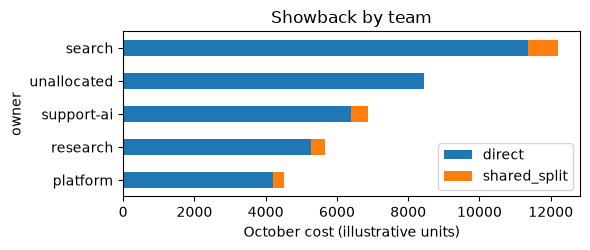

'unallocated' is the cost nobody owns: the tag-compliance list above is how you shrink it.


In [23]:
def owner(tags_json):
    t = json.loads(tags_json)
    if t.get("shared") == "true": return "shared"
    return t["team"] if t.get("team") in TEAMS else "unallocated"
bill["owner"] = bill["Tags"].map(owner)
direct = bill[bill.owner != "shared"].groupby("owner").EffectiveCost.sum()
shared_total = bill[bill.owner == "shared"].EffectiveCost.sum()
teams_only = direct.drop("unallocated", errors="ignore")
split = shared_total * teams_only / teams_only.sum()            # share shared cost proportional to direct cost
showback = pd.DataFrame({"direct": direct, "shared_split": split}).fillna(0)
showback["total"] = showback.sum(axis=1); showback["share_%"] = 100 * showback.total / showback.total.sum()
print(showback.round(0).sort_values("total", ascending=False).to_string())
ax = showback[["direct", "shared_split"]].sort_values("direct").plot.barh(stacked=True, figsize=(6, 2.6))
ax.set_xlabel("October cost (illustrative units)"); ax.set_title("Showback by team"); plt.tight_layout(); plt.show()
print("'unallocated' is the cost nobody owns: the tag-compliance list above is how you shrink it.")

## 15. Unit economics

**What it is:** total cost alone does not say if you are efficient; it grows when the business grows. **Unit economics** divides cost by a unit of value: cost per 1,000 predictions, per active user, per resolved support ticket, per 1M tokens served. If it rises, something got less efficient.

**Simple analogy:** a delivery company tracks cost **per parcel**, not just the fuel bill.

In [24]:
usage = pd.DataFrame({   # made-up monthly business metrics per team
    "owner": ["search", "support-ai", "research"],
    "predictions": [42_000_000, 3_100_000, 250_000],
    "monthly_active_users": [180_000, 25_000, 40],
    "tickets_resolved_by_ai": [0, 61_000, 0],
}).set_index("owner")
ue = showback[["total"]].join(usage, how="inner")
ue["cost_per_1k_predictions"] = 1000 * ue.total / ue.predictions
ue["cost_per_MAU"] = ue.total / ue.monthly_active_users
ue["cost_per_ticket"] = np.where(ue.tickets_resolved_by_ai > 0, ue.total / ue.tickets_resolved_by_ai.replace(0, np.nan), np.nan)
print(ue.round({"total": 0, "cost_per_1k_predictions": 3, "cost_per_MAU": 3, "cost_per_ticket": 3}).to_string())
print("\nresearch has a huge cost per user, which is fine: it is not a product. Always read unit costs with context.")

              total  predictions  monthly_active_users  tickets_resolved_by_ai  cost_per_1k_predictions  cost_per_MAU  cost_per_ticket
owner                                                                                                                                 
research     5663.0       250000                    40                       0                   22.653       141.580              NaN
search      12211.0     42000000                180000                       0                    0.291         0.068              NaN
support-ai   6883.0      3100000                 25000                   61000                    2.220         0.275            0.113

research has a huge cost per user, which is fine: it is not a product. Always read unit costs with context.


## 16. Commitments, reservations and spot

**What it is:** clouds give big discounts if you **commit** to steady usage, and bigger ones for **spare capacity** they can take back.

| Option | AWS | Azure | Google Cloud | Good for |
|---|---|---|---|---|
| **On-demand** | On-Demand | pay-as-you-go | on-demand | spiky, unknown, short-lived |
| **Spend / flexible commitment** (1 or 3 years) | Compute Savings Plans; SageMaker AI Savings Plans | Azure savings plan for compute | spend-based committed use discounts (CUDs) | a steady baseline that may change instance type |
| **Resource commitment** | Reserved Instances (EC2, RDS, ...), EC2 Instance Savings Plans | Azure Reservations | resource-based CUDs | a fixed, well-known fleet |
| **Capacity reservation for GPUs** | On-Demand Capacity Reservations, EC2 Capacity Blocks for ML | capacity reservations | future reservations, calendar-mode reservations | guaranteed GPUs for a training window |
| **Spot / preemptible** | Spot Instances (2-minute interruption notice) | Spot VMs (eviction notice through Scheduled Events, about 30 s) | Spot VMs (about 30 s preemption notice) | fault-tolerant batch: training with checkpoints, batch inference, embeddings backfills |
| **Model API commitments** | Bedrock provisioned throughput | Foundry provisioned throughput units (PTUs) | Agent Platform provisioned throughput | steady, latency-sensitive LLM traffic |

**How to choose a commitment level:** commit to the **baseline** you are confident about (often a low percentile of hourly usage), leave peaks on demand, and use spot for interruptible jobs. Over-committing wastes money just like idle servers.

### 16.1 Runnable: pick a commitment level for a GPU fleet

Discount numbers are **illustrative**: commitment 35% off, spot 65% off.

all on-demand: 7356  |  best commitment: 9 GPUs -> 5635 (23% saved)
for reference, usage percentiles p10/p50/p90 = [ 7. 11. 15.]


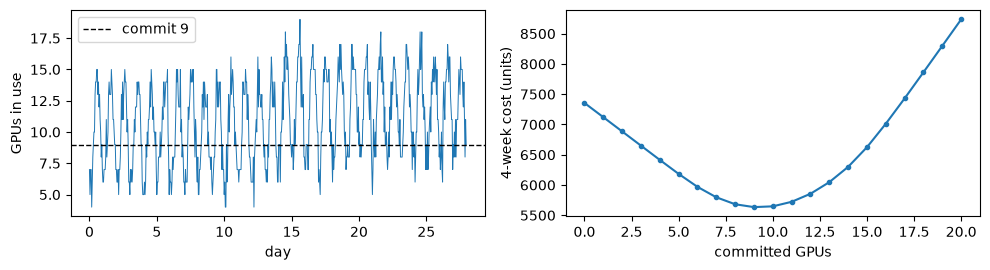

In [25]:
hours = np.arange(24 * 28)
fleet = 10 + 4 * np.sin(2 * np.pi * (hours % 24 - 8) / 24) + rng.normal(0, 1.2, hours.size)   # GPUs in use per hour
fleet = np.clip(np.round(fleet + (hours > 24 * 14) * 2), 2, None)                              # growth in week 3
RATE, COMMIT_DISC = 1.0, 0.35

def cost_with_commit(c):
    committed = c * hours.size * RATE * (1 - COMMIT_DISC)          # you pay for the commitment, used or not
    overflow = np.clip(fleet - c, 0, None).sum() * RATE             # the rest at on-demand price
    return committed + overflow

levels = np.arange(0, 21)
costs = np.array([cost_with_commit(c) for c in levels])
best = levels[costs.argmin()]
print(f"all on-demand: {costs[0]:.0f}  |  best commitment: {best} GPUs -> {costs.min():.0f} ({1 - costs.min() / costs[0]:.0%} saved)")
print(f"for reference, usage percentiles p10/p50/p90 = {np.percentile(fleet, [10, 50, 90])}")
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))
ax[0].plot(hours / 24, fleet, lw=0.7); ax[0].axhline(best, color="k", ls="--", lw=1, label=f"commit {best}")
ax[0].set_xlabel("day"); ax[0].set_ylabel("GPUs in use"); ax[0].legend()
ax[1].plot(levels, costs, marker="o", ms=3); ax[1].set_xlabel("committed GPUs"); ax[1].set_ylabel("4-week cost (units)")
plt.tight_layout(); plt.show()

In [26]:
# Spot for a 100-hour training job: interruptions lose the work since the last checkpoint.
def spot_job(work_h=100, interrupt_per_h=0.03, ckpt_every_h=1.0, ckpt_cost_h=0.05, restart_h=0.25, runs=400):
    r = np.random.default_rng(SEED); walls = []
    for _ in range(runs):
        done, wall = 0.0, 0.0
        while done < work_h:
            seg = min(ckpt_every_h, work_h - done)
            t_fail = r.exponential(1 / interrupt_per_h)
            if t_fail >= seg + ckpt_cost_h:
                done += seg; wall += seg + ckpt_cost_h
            else:
                wall += t_fail + restart_h                          # lost the partial segment, then restart
        walls.append(wall)
    return np.mean(walls)

print("on-demand: 100 h x 1.00 = 100 units")
for ck in (0.25, 1, 4, 12):
    w = spot_job(ckpt_every_h=ck)
    print(f"spot, checkpoint every {ck:>5} h: wall time {w:6.1f} h, cost {w * 0.35:5.1f} units")
print("too-frequent checkpoints waste time saving; too-rare ones lose more work per interruption: pick the middle")

on-demand: 100 h x 1.00 = 100 units
spot, checkpoint every  0.25 h: wall time  121.5 h, cost  42.5 units


spot, checkpoint every     1 h: wall time  107.5 h, cost  37.6 units
spot, checkpoint every     4 h: wall time  108.7 h, cost  38.0 units
spot, checkpoint every    12 h: wall time  120.8 h, cost  42.3 units
too-frequent checkpoints waste time saving; too-rare ones lose more work per interruption: pick the middle


## 17. Kubernetes cost monitoring: OpenCost and Kubecost

**What it is:** a cloud bill shows **nodes**, not which team's pods ran on them. **OpenCost** (an open-source CNCF incubating project) and **Kubecost** (its commercial sibling, owned by IBM since 2024) read Kubernetes resource requests and usage plus cloud prices, and allocate node cost to namespaces, labels, deployments and pods. Cloud-native options exist too (for example AWS split cost allocation data for EKS, AKS cost analysis, GKE cost allocation).

**How it works:** each pod is charged for the larger of what it **requested** and what it **used** (requested capacity is reserved, so others cannot use it). Whatever is left on the node is **idle** cost, which is a sign of over-provisioned nodes or over-sized requests. GPUs are allocated per whole GPU (or per MIG slice or time-slice).

**Simple analogy:** a shared flat. Each person pays for the room they reserved, even if they are rarely home; the empty spare room is the "idle" cost everyone shares or eliminates.

In [27]:
NODES = {"cpu-node-1": {"cpu": 16, "mem": 64, "gpu": 0, "price_h": 0.8},
         "gpu-node-1": {"cpu": 32, "mem": 128, "gpu": 4, "price_h": 12.0}}
PODS = [  # (pod, namespace, node, cpu req, cpu used, mem req GB, mem used GB, gpus)
    ("rag-api-1", "search", "cpu-node-1", 2, 1.2, 4, 3, 0), ("rag-api-2", "search", "cpu-node-1", 2, 1.0, 4, 3, 0),
    ("embedder", "search", "gpu-node-1", 4, 3, 16, 12, 1), ("vllm-chat", "support-ai", "gpu-node-1", 8, 6, 48, 40, 2),
    ("notebook-ana", "research", "gpu-node-1", 4, 0.2, 16, 2, 1), ("prometheus", "platform", "cpu-node-1", 2, 1.5, 8, 6, 0),
]
def allocate(nodes, pods, hours=730):
    rows = []
    for name, n in nodes.items():
        # split node price into CPU / memory / GPU parts (illustrative weights)
        w = {"gpu": 0.85, "cpu": 0.10, "mem": 0.05} if n["gpu"] else {"gpu": 0, "cpu": 0.65, "mem": 0.35}
        unit = {k: n["price_h"] * w[k] / n[k] if n[k] else 0 for k in ("cpu", "mem", "gpu")}
        used = {"cpu": 0, "mem": 0, "gpu": 0}
        for p, ns, node, creq, cuse, mreq, muse, g in pods:
            if node != name: continue
            alloc = {"cpu": max(creq, cuse), "mem": max(mreq, muse), "gpu": g}
            for k in used: used[k] += alloc[k]
            cost = sum(alloc[k] * unit[k] for k in alloc) * hours
            eff = (cuse + muse / 4) / (creq + mreq / 4)              # rough efficiency score
            rows.append((ns, p, round(cost), f"{eff:.0%}"))
        idle = sum((n[k] - used[k]) * unit[k] for k in used) * hours
        rows.append(("__idle__", name, round(idle), "-"))
    return pd.DataFrame(rows, columns=["namespace", "pod / node", "monthly_cost", "cpu+mem efficiency"])

alloc = allocate(NODES, PODS)
print(alloc.to_string(index=False))
print("\nby namespace:", alloc.groupby("namespace").monthly_cost.sum().sort_values(ascending=False).to_dict())
print("notebook-ana holds a whole GPU at about 10% efficiency: candidate for MIG / time-slicing or auto-stop.")

 namespace   pod / node  monthly_cost cpu+mem efficiency
    search    rag-api-1            60                65%
    search    rag-api-2            60                58%
  platform   prometheus            73                75%
  __idle__   cpu-node-1           391                  -
    search     embedder          2026                75%
support-ai    vllm-chat          4106                80%
  research notebook-ana          2026                 9%
  __idle__   gpu-node-1           602                  -

by namespace: {'support-ai': 4106, 'search': 2146, 'research': 2026, '__idle__': 993, 'platform': 73}
notebook-ana holds a whole GPU at about 10% efficiency: candidate for MIG / time-slicing or auto-stop.


## 18. Off-hours shutdown scheduling

**What it is:** dev, staging and notebook machines often run 24/7 but are used about 50 hours a week. **Scheduled stop/start** and **idle auto-stop** remove most of that waste.

**Tools:** AWS Instance Scheduler and EventBridge Scheduler, Azure VM auto-shutdown and Azure Automation start/stop, Google Cloud instance schedules; idle shutdown for managed notebooks (SageMaker AI Studio, Azure Machine Learning compute instances, Vertex / Agent Platform Workbench); for Kubernetes, scale-to-zero with KEDA's cron scaler or kube-downscaler, and node autoscalers (Karpenter, Cluster Autoscaler) that then remove empty nodes.

**When not to:** shared services with users in other time zones, or anything whose cold start is very long (warm a few minutes before the working day instead).

In [28]:
week = pd.date_range("2026-11-16", periods=24 * 7, freq="h")          # Monday 00:00 to Sunday 23:00
schedule_on = (week.day_of_week < 5) & (week.hour >= 8) & (week.hour < 19)  # Mon-Fri 08:00-19:00
# simulated real activity of one developer's GPU box: busy blocks on some weekdays
active = np.zeros(len(week), dtype=bool)
for d in (0, 1, 3):                                                    # Mon, Tue, Thu
    s = 24 * d + random.randint(9, 11); active[s:s + random.randint(3, 6)] = True

def idle_stop(active, idle_limit_h=1):
    on, idle, out = False, 0, []
    for a in active:
        if a: on, idle = True, 0
        elif on:
            idle += 1
            if idle > idle_limit_h: on = False
        out.append(on)
    return np.array(out)

GPU_RATE = 3.0  # illustrative units per hour
plans = {"24/7": np.ones(len(week), bool), "schedule Mon-Fri 8-19": schedule_on, "idle auto-stop (1 h)": idle_stop(active)}
rows = [{"plan": k, "hours_on": int(v.sum()), "weekly_cost": v.sum() * GPU_RATE,
         "active_hours_covered": f"{(v & active).sum()}/{active.sum()}"} for k, v in plans.items()]
out = pd.DataFrame(rows); out["saving_vs_24/7"] = (1 - out.weekly_cost / out.weekly_cost[0]).map("{:.0%}".format)
print(out.to_string(index=False))

                 plan  hours_on  weekly_cost active_hours_covered saving_vs_24/7
                 24/7       168        504.0                12/12             0%
schedule Mon-Fri 8-19        55        165.0                12/12            67%
 idle auto-stop (1 h)        15         45.0                12/12            91%


## 19. GPU idle detection

**What it is:** GPUs are usually the largest line item, and they are often **allocated but idle**: a forgotten notebook, a model server for a feature nobody uses at night, an over-provisioned replica count. NVIDIA's **DCGM exporter** publishes per-GPU metrics to Prometheus, for example `DCGM_FI_DEV_GPU_UTIL` (utilisation %) and `DCGM_FI_DEV_FB_USED` (memory used). A simple rule flags long stretches of low utilisation.

**Careful:** "GPU utilisation" only says that *some* kernel was running; it does not measure how full the GPU was. For efficiency use SM activity / occupancy metrics (`DCGM_FI_PROF_SM_ACTIVE`). For **idle** detection, plain utilisation is good enough.

```promql
# GPUs below 5% utilisation for the last 6 hours (Prometheus, shown not run)
max_over_time(DCGM_FI_DEV_GPU_UTIL[6h]) < 5
```

       gpu  mean_util_%  idle_hours  longest_idle_h  wasted_cost                             action
node0/gpu0         69.8           0               0          0.0                                 ok
node0/gpu1         70.0           0               0          0.0                                 ok
node0/gpu2         17.1         121              27        302.5 schedule or share (MIG/time-slice)
node0/gpu3          1.0         168             168        420.0            release / scale to zero
node1/gpu0          1.8         165              93        412.5            release / scale to zero
node1/gpu1         15.5         138             138        345.0            release / scale to zero
node1/gpu2          2.3         161              69        402.5            release / scale to zero
node1/gpu3          2.2         161             133        402.5            release / scale to zero

wasted this week: 2285 units of 3360 (68%)


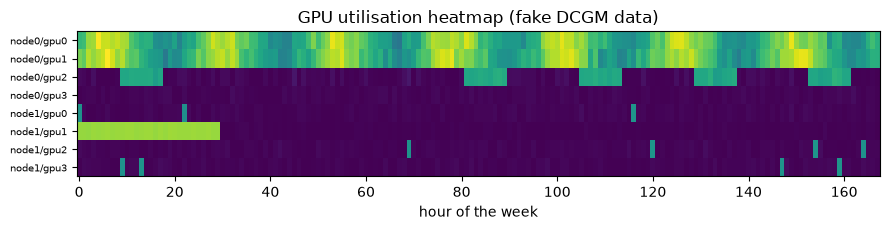

In [29]:
gpus = [f"node{n}/gpu{g}" for n in range(2) for g in range(4)]
t = pd.date_range("2026-11-06", periods=24 * 7, freq="h")
util = pd.DataFrame(index=t)
for i, g in enumerate(gpus):
    hour = t.hour.values
    if i in (0, 1):   u = 70 + 20 * np.sin(2 * np.pi * hour / 24) + rng.normal(0, 5, len(t))       # busy serving
    elif i == 2:      u = np.where((hour >= 9) & (hour < 18) & (t.day_of_week.values < 5), 60, 1) + rng.normal(0, 2, len(t))  # office hours
    elif i == 5:      u = np.where(np.arange(len(t)) < 30, 85, 0.5) + rng.normal(0, 0.5, len(t))     # job finished, never released
    else:             u = rng.normal(1, 0.8, len(t)) + (rng.random(len(t)) < 0.03) * 50              # mostly idle
    util[g] = np.clip(u, 0, 100)

def idle_episodes(series, threshold=5, min_hours=6):
    low = (series < threshold).astype(int).values
    eps, start = [], None
    for i, v in enumerate(np.append(low, 0)):
        if v and start is None: start = i
        if not v and start is not None:
            if i - start >= min_hours: eps.append(i - start)
            start = None
    return eps

RATE_GPU_H = 2.5   # illustrative units per GPU-hour
rep = pd.DataFrame([{"gpu": g, "mean_util_%": util[g].mean(), "idle_hours": sum(idle_episodes(util[g])),
                     "longest_idle_h": max(idle_episodes(util[g]) or [0])} for g in gpus])
rep["wasted_cost"] = rep.idle_hours * RATE_GPU_H
rep["action"] = np.select([rep.longest_idle_h >= 48, rep.idle_hours > 40], ["release / scale to zero", "schedule or share (MIG/time-slice)"], "ok")
print(rep.round(1).to_string(index=False))
print(f"\nwasted this week: {rep.wasted_cost.sum():.0f} units of {len(gpus) * len(t) * RATE_GPU_H:.0f} ({rep.wasted_cost.sum() / (len(gpus) * len(t) * RATE_GPU_H):.0%})")
fig, ax = plt.subplots(figsize=(9, 2.4))
ax.imshow(util.T.values, aspect="auto", cmap="viridis", interpolation="nearest")
ax.set_yticks(range(len(gpus))); ax.set_yticklabels(gpus, fontsize=7); ax.set_xlabel("hour of the week")
ax.set_title("GPU utilisation heatmap (fake DCGM data)"); plt.tight_layout(); plt.show()

## 20. LLM token cost governance and cost anomalies

**What it is:** for API-based models the bill is **tokens**, and it can grow 10x overnight from one prompt change or a looping agent ("denial of wallet"). Governance means: every call goes through a **gateway** that attributes it to a team and feature, **budgets** with alerts, **rate and spend limits** per key or team, and **anomaly detection** on daily spend. Pricing, prompt caching, batch APIs and model routing are in [Tokens, cost, batch and caching](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb).

**Tools:** cloud budgets and anomaly detection (AWS Budgets and Cost Anomaly Detection, Azure Cost Management budgets and anomaly alerts, Google Cloud budgets and anomaly detection), provider-side project limits, and LLM gateways (LiteLLM, Cloudflare AI Gateway, Azure API Management AI gateway, Kong AI Gateway, Portkey and similar) that track tokens per key.

The cell checks month-to-date spend per team against budgets (alerts at 50/80/100%) and flags anomalous days with a robust rule: today versus the median of the previous 7 days, measured in MADs (median absolute deviations), which ignores normal noise better than a mean.

In [30]:
d = pd.date_range("2026-11-01", "2026-11-13", freq="D")
spend = pd.DataFrame({"search": 120 + rng.normal(0, 8, len(d)), "support-ai": 300 + rng.normal(0, 20, len(d)),
                      "research": 60 + rng.normal(0, 15, len(d))}, index=d)
spend.loc["2026-11-11":, "support-ai"] += 450        # an agent started looping on the 11th
BUDGET = {"search": 4000, "support-ai": 9000, "research": 2500}   # monthly, illustrative units

mtd = spend.sum()
for team, b in BUDGET.items():
    pct = 100 * mtd[team] / b
    level = next((lvl for lvl in (100, 80, 50) if pct >= lvl), None)
    forecast = mtd[team] / len(d) * 30
    print(f"{team:<11} month-to-date {mtd[team]:7.0f} = {pct:5.1f}% of budget"
          + (f"  -> ALERT {level}%" if level else "") + f"   forecast for month: {forecast:7.0f}")

def anomalies(s, k=5):
    out = []
    for i in range(7, len(s)):
        hist = s.iloc[i - 7:i]; med = hist.median(); mad = (hist - med).abs().median() + 1e-9
        if (s.iloc[i] - med) / (1.4826 * mad) > k:
            out.append((s.index[i].date(), round(s.iloc[i]), round(med)))
    return out
for team in spend:
    for day, val, med in anomalies(spend[team]):
        print(f"ANOMALY {team}: {day} spend {val} vs 7-day median {med}")

search      month-to-date    1532 =  38.3% of budget   forecast for month:    3536
support-ai  month-to-date    5257 =  58.4% of budget  -> ALERT 50%   forecast for month:   12132
research    month-to-date     755 =  30.2% of budget   forecast for month:    1742
ANOMALY support-ai: 2026-11-11 spend 767 vs 7-day median 308
ANOMALY support-ai: 2026-11-12 spend 728 vs 7-day median 310
ANOMALY support-ai: 2026-11-13 spend 767 vs 7-day median 310


# Part D: Serverless and edge for AI

## 21. Serverless, edge and backend-as-a-service

**What it is:**
- **Serverless functions (FaaS)**: you upload a function; the platform runs it on demand, scales it (including to zero) and bills per request and execution time. You do not manage servers.
- **Serverless containers**: the same idea for a whole container (Cloud Run, Azure Container Apps, AWS Fargate with ECS Express Mode).
- **Edge functions**: small functions that run in many locations close to users, often in lightweight **V8 isolates** or **WebAssembly** instead of containers.
- **Backend-as-a-service (BaaS)**: a hosted database, auth, storage and functions that the frontend talks to directly (Supabase, Firebase).

**Simple analogy:** serverless is a taxi (pay per ride, no car to maintain, but you wait for one to arrive), a reserved VM is owning a car, and the edge is a taxi rank on every street corner.

| Platform | Type | AI-relevant notes (as of late 2026) |
|---|---|---|
| **AWS Lambda** | functions | max 15 min per invocation, up to 10,240 MB memory, 6 MB sync request/response payload, response streaming up to 200 MB; container images up to 10 GB; SnapStart and provisioned concurrency against cold starts; **durable functions** (multi-step workflows that can pause and resume) and **Lambda Managed Instances** (Lambda on EC2 capacity you choose) launched at re:Invent 2025. No GPUs |
| **Azure Functions** | functions | the **Flex Consumption** plan is the recommended serverless plan, with "always ready" instances to avoid cold starts; Durable Functions for workflows |
| **Cloud Run functions** (formerly Cloud Functions) and **Cloud Run** | functions / containers | Cloud Run supports NVIDIA L4 GPUs with scale to zero (one GPU per instance), good for small open models |
| **Azure Container Apps** | containers | serverless GPUs, dynamic sessions (sandboxed code execution for agents) |
| **Cloudflare Workers** | edge isolates | 128 MB memory per isolate; CPU time limit 10 ms on the free plan and up to 5 minutes on paid (waiting on network does not count). **Workers AI** runs models on Cloudflare's GPUs, **AI Gateway** proxies and logs LLM calls, **Vectorize** is a vector index, Durable Objects keep state |
| **Vercel Functions** / **Netlify Functions** | functions for web apps | Vercel's **Fluid compute** (default for new projects since April 2025) lets one instance serve many concurrent requests, which suits I/O-bound LLM streaming; both are common for Next.js AI frontends and API routes |
| **Deno Deploy**, **Fly.io**, **Render**, **Railway** | edge / PaaS | simple app hosting; Fly.io offers GPU machines in some regions |
| **Modal**, **RunPod**, **Replicate**, **Baseten** | serverless GPU | covered in [serverless deployment](../16_Deployment/03_serverless_deployment.ipynb) |
| **Supabase** | BaaS on Postgres | auth, storage, edge functions, `pgvector`; the browser talks to the database through an auto-generated API |
| **Firebase** | BaaS (Google) | Firestore, auth, Cloud Functions, Firebase AI Logic for calling Gemini from apps |

**BaaS security caveat:** with Supabase the client-side key is **public by design**; what protects your data is **Row Level Security (RLS)** policies in Postgres. Tables created through the dashboard get RLS enabled by default, but tables created with SQL do not, and a table without RLS can be read (and written) by anyone with the public key. Firebase has the same pattern with **Security Rules**. AI-generated ("vibe-coded") apps frequently ship with these off; see [Securing vibe-coded applications](../27_AI_and_Cybersecurity/02_securing_vibe_coded_applications.ipynb). Never put LLM provider keys in frontend code: call the model from a function that checks the user and enforces limits.

```mermaid
flowchart LR
    B[Browser / app] --> EF[Edge function: auth check, rate limit, cache]
    EF --> GW[AI gateway: keys, logging, token budgets]
    GW --> LLM[LLM API or Workers AI]
    EF --> DB[(BaaS Postgres with RLS + pgvector)]
    EF -. long jobs .-> Q[Queue] --> W[Container or durable function worker]
```

### 21.1 Cold starts: a runnable simulation

**What it is:** a **cold start** happens when a request arrives and no warm instance exists: the platform must start a runtime, load your code and, for AI, **load the model** into memory. Then that request waits seconds instead of milliseconds. Instances are kept warm for a while after each request and then reclaimed.

**Mitigations:** keep a minimum number of warm instances (provisioned concurrency on Lambda, always-ready on Azure Flex Consumption, `min-instances` on Cloud Run), make start-up fast (small images, lazy imports, SnapStart, load models from a fast local cache or a memory-mapped format like safetensors), and keep big models out of functions entirely (call a model server or API instead).

We simulate one day of bursty, low traffic and compare a small model (0.5 s load) and a bigger one (8 s load), with 0 or 1 minimum warm instances. Times and prices are illustrative.

In [31]:
def simulate_cold_starts(model_load_s, min_instances, idle_timeout_s=600, seed=SEED):
    r = np.random.default_rng(seed)
    # arrival rate per minute over a day: quiet night, busy working hours
    rate = np.array([0.05 if h < 7 or h >= 22 else (1.5 if 9 <= h < 18 else 0.4) for h in range(24) for _ in range(60)])
    arrivals = np.sort(np.concatenate([m * 60 + r.uniform(0, 60, r.poisson(lam)) for m, lam in enumerate(rate)]))
    last, lat, cold = -1e9, [], 0
    for t in arrivals:
        warm = min_instances > 0 or (t - last) < idle_timeout_s
        service = r.lognormal(np.log(0.3), 0.3)
        if not warm:
            cold += 1; service += 0.8 + model_load_s                 # runtime init + model load
        lat.append(service); last = t
    lat = np.array(lat)
    busy_s = lat.sum(); always_on_s = min_instances * 86400
    cost = busy_s * 1.0 + always_on_s * 0.25                         # illustrative: idle warm capacity is cheaper but not free
    return {"requests": len(lat), "cold_%": 100 * cold / len(lat), "p50_s": np.median(lat),
            "p99_s": np.percentile(lat, 99), "max_s": lat.max(), "cost_units": cost / 1000}

rows = [{"model": f"{name} ({load} s load)", "min_instances": mi, **simulate_cold_starts(load, mi)}
        for name, load in [("small", 0.5), ("big", 8.0)] for mi in (0, 1)]
print(pd.DataFrame(rows).round(2).to_string(index=False))

             model  min_instances  requests  cold_%  p50_s  p99_s  max_s  cost_units
small (0.5 s load)              0       962    1.98    0.3   1.63   1.86        0.33
small (0.5 s load)              1       962    0.00    0.3   0.62   0.85       21.90
  big (8.0 s load)              0       962    1.98    0.3   9.13   9.36        0.47
  big (8.0 s load)              1       962    0.00    0.3   0.62   0.85       21.90


**Reading the results:** with scale to zero, a few percent of requests are cold, which barely moves the median but dominates the **p99** and the worst case, especially with the big model. One warm instance removes cold starts but costs money every hour of the day. That is the core serverless trade-off: **pay for idle capacity or accept tail latency**.

**When serverless fits AI, and when it does not:**

| Fits well | Fits poorly |
|---|---|
| glue around model APIs: auth, routing, prompt assembly, tool endpoints, webhooks | hosting large models that need GPUs and tens of GB of memory (use Cloud Run GPUs, serverless GPU platforms, or a model server) |
| event-driven pipelines: a file lands in storage, then chunk, embed and index it | long-running agents or training (time limits; use durable functions, workflows or containers) |
| spiky or low traffic, internal tools, prototypes | steady high traffic, where per-request pricing costs more than reserved capacity |
| edge: geo-routing, caching, rate limiting, small classifiers or Workers AI calls near users | latency-critical paths that cannot tolerate cold starts unless you pay for warm instances |
| MCP servers and tool APIs for agents with bursty use | workloads that need local disk state or fixed IPs (possible, but awkward) |

The original serverless notebook ([serverless deployment](../16_Deployment/03_serverless_deployment.ipynb)) shows SageMaker AI serverless endpoints, Modal and Cloud Run deployments; [edge deployment](../16_Deployment/04_edge_deployment.ipynb) covers on-device and edge hardware.

```python
# AWS Lambda handler that calls a model API with a short timeout (shown, not run)
import json, os, urllib.request
def handler(event, context):
    body = json.loads(event["body"])
    req = urllib.request.Request(os.environ["MODEL_URL"], data=json.dumps({"q": body["q"]}).encode(),
                                 headers={"Authorization": f"Bearer {os.environ['TOKEN_FROM_SECRETS_MANAGER']}"})
    with urllib.request.urlopen(req, timeout=20) as r:      # stay well below the function timeout
        return {"statusCode": 200, "body": r.read().decode()}
```

```javascript
// Cloudflare Worker calling Workers AI (shown, not run)
export default {
  async fetch(request, env) {
    const { prompt } = await request.json();
    const answer = await env.AI.run("@cf/meta/llama-3.1-8b-instruct", { prompt });
    return Response.json(answer);
  },
};
```

## 22. Service map

| Need | AWS | Azure | Google Cloud | Open source / vendor-neutral |
|---|---|---|---|---|
| Incident management, on-call | AWS Systems Manager Incident Manager | Azure Monitor alerts + action groups | Cloud Monitoring alerting | PagerDuty, Opsgenie, incident.io, Grafana OnCall |
| Chaos experiments | AWS Fault Injection Service | Azure Chaos Studio | (use open source on GKE) | Chaos Mesh, LitmusChaos, Gremlin, Toxiproxy |
| Continuous profiling | CodeGuru Profiler | Application Insights Profiler | Cloud Profiler | Pyroscope, Parca, OTel Profiles (alpha) |
| LLM tracing | Bedrock AgentCore Observability, CloudWatch | Foundry observability, Application Insights | Agent Platform observability, Cloud Trace | Langfuse, Phoenix, OpenLLMetry, LangSmith |
| Workload identity | IAM roles, EKS Pod Identity | managed identities, workload identity federation | service accounts, Workload Identity Federation | SPIFFE/SPIRE |
| Private access to services | VPC endpoints / PrivateLink | Private Link / private endpoints | Private Service Connect | |
| Secrets | Secrets Manager, Parameter Store | Key Vault | Secret Manager | Vault / OpenBao, External Secrets, SOPS |
| Keys and encryption | KMS, CloudHSM | Key Vault, Managed HSM | Cloud KMS, Cloud HSM | |
| Posture and threats | Security Hub (CSPM), GuardDuty, Inspector, Macie | Defender for Cloud | Security Command Center | Prowler, Checkov, Trivy, Kubescape, Falco |
| Compliance evidence | AWS Artifact, Audit Manager, Config | Service Trust Portal, Purview Compliance Manager, Azure Policy | Compliance Reports Manager, Audit Manager | Vanta, Drata, Secureframe |
| Billing export and FOCUS | Data Exports (CUR 2.0, FOCUS) | Cost Management exports (FOCUS) | Cloud Billing export to BigQuery (FOCUS view) | FOCUS spec, OpenCost |
| Budgets and anomalies | AWS Budgets, Cost Anomaly Detection | Cost Management budgets and anomaly alerts | Budgets and alerts, cost anomaly detection | |
| Tag enforcement | Organizations tag policies, SCPs, Config rules | Azure Policy | organisation policies, labels | IaC policy checks (OPA, Checkov) |
| Commitments and spot | Savings Plans, RIs, Spot | Reservations, savings plan, Spot VMs | CUDs, Spot VMs | |
| Scheduled stop/start | Instance Scheduler, EventBridge Scheduler | VM auto-shutdown, Automation | instance schedules | KEDA cron, kube-downscaler |
| Kubernetes cost | split cost allocation for EKS | AKS cost analysis | GKE cost allocation | OpenCost, Kubecost |
| Serverless functions | Lambda | Functions (Flex Consumption) | Cloud Run functions | Knative, OpenFaaS |
| Serverless containers / GPUs | ECS Express Mode, Fargate | Container Apps (serverless GPUs) | Cloud Run (GPUs) | Modal, RunPod, Baseten |
| Edge | CloudFront Functions, Lambda@Edge | Front Door rules | Cloud CDN, Media CDN | Cloudflare Workers, Vercel, Netlify, Fastly Compute |

## 23. How to try it for real (free or local)

- **Chaos on a laptop cluster:** create a cluster with `kind` or `minikube`, install Chaos Mesh or LitmusChaos with Helm, deploy two small services and inject `NetworkChaos` delay between them while watching a Grafana dashboard. Toxiproxy works without Kubernetes.
- **Profiling:** `pip install py-spy` and run `py-spy top --pid <PID>` or `py-spy record -o flame.svg -- python app.py`; run Grafana Pyroscope locally with its Docker image and point the Python SDK at it.
- **LLM tracing:** self-host Langfuse with its Docker Compose file, or `pip install arize-phoenix` and launch Phoenix locally; send traces from a fake LLM app with OpenTelemetry.
- **Posture scanning:** run Prowler against a free-tier AWS, Azure or Google Cloud account (read-only role), Checkov or Trivy against your Terraform folder, and kube-bench / Kubescape against a `kind` cluster.
- **Secrets:** run HashiCorp Vault or OpenBao in dev mode in Docker; LocalStack emulates AWS Secrets Manager and KMS locally.
- **FinOps:** enable the FOCUS export on a free-tier account and load it into pandas or DuckDB; install OpenCost on `kind` with Prometheus to see namespace allocation; set a small budget with an email alert.
- **Serverless:** AWS SAM CLI or LocalStack for Lambda, Azure Functions Core Tools with Azurite, the Google Functions Framework, `wrangler dev` for Cloudflare Workers, and the Supabase CLI (`supabase start`) for a local Postgres with RLS to test policies.

## 24. Certification topic map

| Certification (named generally) | Topics from this notebook |
|---|---|
| Google Professional Cloud DevOps Engineer | SLOs, error budgets, incident management, postmortems, toil, observability |
| AWS DevOps Engineer Professional, AWS CloudOps Engineer Associate | incident response, FIS, monitoring, cost controls, Lambda operations |
| AWS Security Specialty, Azure Security Engineer (AZ-500), Google Professional Cloud Security Engineer, Microsoft SC-100 | zero trust, identity, segmentation, secrets, KMS, posture management, compliance evidence |
| CNCF CKS (Kubernetes security) | NetworkPolicies, secrets, runtime security, supply chain |
| FinOps Certified Practitioner, FinOps for AI (FinOps Foundation) | Inform / Optimize / Operate, tagging, showback, unit economics, commitments, anomaly detection |
| ISO/IEC 27001 and ISO/IEC 42001 lead implementer / auditor courses; ISC2 CCSP | controls, evidence, shared responsibility, AI management systems |
| AWS Generative AI Developer Professional (AIP-C01), Azure AI-103 | LLM observability, cost governance, serverless integration of model APIs |

## Recap: cheat sheet

| Topic | Remember |
|---|---|
| SLO / error budget | the budget is permission to change; spend it on releases, stop when it runs out |
| Incident roles | IC coordinates, Ops lead changes production, Comms lead updates people, scribe keeps the timeline |
| Severity | decide levels in advance; data exposure and leaked keys are top severity even if few users are affected |
| On-call and runbooks | page on symptoms (SLO burn), link every alert to a runbook, fair rotations |
| Postmortems | blameless, contributing factors, owned and dated action items |
| Toil | manual, repetitive, automatable work; keep it under half of the team's time |
| Chaos engineering | steady state, hypothesis, small blast radius, abort conditions, automate; test latency faults, not only outages |
| Continuous profiling | always-on sampling, flame graphs, eBPF; OTel Profiles is alpha |
| LLM observability | GenAI semconv (`gen_ai.*`), tokens, TTFT, cost per request and per feature, alerts on cost per request |
| Zero trust | verify every request by identity, posture and context; least privilege; agents are identities |
| Segmentation | private subnets, private endpoints, egress allow-lists, no public SSH |
| Secrets | central manager, workload identity instead of keys, rotation with overlap, emergency revoke on leaks |
| Encryption | TLS / mTLS in transit, KMS envelope encryption at rest, confidential computing in use |
| CSPM / CNAPP | continuous config scanning, CIEM for permissions, AI-SPM for model endpoints |
| Compliance | SOC 2 (attestation), ISO 27001 / 42001 (certification), HIPAA (BAA), GDPR, EU AI Act; automate evidence; not legal advice |
| FinOps | Inform, Optimize, Operate; FOCUS exports; tags with enforcement; showback; unit costs |
| Commitments / spot | commit to the baseline, on-demand for peaks, spot with checkpoints for batch |
| Kubernetes cost | max(request, usage) per pod; idle cost shows over-provisioning |
| Idle waste | off-hours schedules, idle auto-stop, GPU idle rules on DCGM metrics |
| Token governance | gateway attribution, budgets 50/80/100%, robust anomaly detection |
| Serverless | great glue and event processing; cold starts and limits; big models need GPUs elsewhere; RLS for BaaS |

## Interview questions

1. **What does an Incident Commander do, and what do they avoid doing?** Coordinates the response, assigns roles and decides priorities and when the incident ends. They avoid hands-on debugging so that someone always has the overall picture.
2. **What makes a postmortem "blameless", and why does it matter?** It looks for system causes and improvements instead of individual fault. People then report problems honestly, so the organisation learns.
3. **Design a chaos experiment for a RAG service.** Steady state: success rate and p95 latency SLIs. Hypothesis: if the primary LLM provider slows by 3 s, fallback and timeouts keep the SLI above 99%. Inject latency on the LLM egress in staging for 5 minutes with Chaos Mesh or AWS FIS, abort if burn rate is greater than 10, compare, fix, automate.
4. **Why profile continuously instead of only when there is a problem?** Regressions show up as a diff between versions, and rare slow paths only appear under real traffic. Sampling profilers are cheap enough to leave on.
5. **Which attributes would you record on an LLM span?** Operation, provider, requested and response model, input and output tokens, finish reason, error type, TTFT and duration, plus app attributes (feature, tenant, prompt version). Record content only with redaction.
6. **How do you rotate an LLM API key without downtime?** Create a second key, publish it as the current secret version, wait for all clients to refresh (or push a reload), then revoke the old key and watch for errors. For a leaked key, revoke at once.
7. **What is envelope encryption, and why is KEK rotation cheap?** Data is encrypted with per-object data keys, and the data keys are encrypted by a master key in the KMS. Rotating the master key only re-wraps the small data keys.
8. **CSPM vs CNAPP?** CSPM scans cloud configuration for risky settings. CNAPP is a platform that combines CSPM with workload protection, entitlement management, data and AI posture, IaC scanning and runtime detection.
9. **SOC 2 Type I vs Type II? ISO 27001 vs ISO 42001?** Type I: controls are designed correctly at a point in time. Type II: they operated effectively over a period. ISO 27001 certifies an information security management system; ISO 42001 certifies an AI management system.
10. **How would you cut a GPU bill by 30% without hurting users?** Tag and show back costs, find idle GPUs (DCGM rules) and forgotten notebooks, schedule dev and staging off-hours, right-size requests and share GPUs (MIG or time-slicing), commit to the steady baseline, move batch work to spot with checkpoints, and track cost per 1k predictions.
11. **When is serverless a bad fit for AI inference?** Large GPU models, steady high traffic, long-running jobs, or strict tail-latency needs without paying for warm instances.
12. **Why is a public Supabase key not a leak, and what is the real risk?** The key is meant to be public; access is controlled by Row Level Security policies. The risk is tables without RLS, or with policies that are too broad.

## Further reading

**SRE and chaos**
- B. Beyer et al., *Site Reliability Engineering* (2016) and *The Site Reliability Workbook* (2018), free at https://sre.google/books/ : chapters "Eliminating Toil", "Managing Incidents", "Postmortem Culture", "Incident Response".
- Google, "Incident Management Guide": https://sre.google/resources/practices-and-processes/incident-management-guide/
- Principles of Chaos Engineering: https://principlesofchaos.org
- Chaos Mesh: https://chaos-mesh.org ; LitmusChaos: https://litmuschaos.io ; AWS Fault Injection Service: https://docs.aws.amazon.com/fis/ ; Azure Chaos Studio: https://learn.microsoft.com/azure/chaos-studio/

**Profiling and LLM observability**
- OpenTelemetry, "OpenTelemetry Profiles Enters Public Alpha" (2026): https://opentelemetry.io/blog/2026/profiles-alpha
- Grafana Pyroscope: https://grafana.com/oss/pyroscope/ ; Parca: https://www.parca.dev
- OpenTelemetry semantic conventions for generative AI: https://opentelemetry.io/docs/specs/semconv/gen-ai/
- Langfuse: https://langfuse.com/docs ; Arize Phoenix: https://docs.arize.com/phoenix ; ClickHouse, "ClickHouse welcomes Langfuse" (January 2026).

**Security and compliance**
- NIST SP 800-207, *Zero Trust Architecture* (2020): https://csrc.nist.gov/pubs/sp/800/207/final
- AWS Secrets Manager rotation: https://docs.aws.amazon.com/secretsmanager/latest/userguide/rotating-secrets.html ; Azure Key Vault: https://learn.microsoft.com/azure/key-vault/ ; Google Secret Manager: https://cloud.google.com/secret-manager/docs
- AWS Security Hub user guide ("Security Hub and Security Hub CSPM"): https://docs.aws.amazon.com/securityhub/latest/userguide/
- AICPA SOC 2 overview: https://www.aicpa-cima.com/topic/audit-assurance/audit-and-assurance-greater-than-soc-2 ; ISO/IEC 27001:2022 and ISO/IEC 42001:2023 at https://www.iso.org
- EU AI Act text and the Digital Omnibus on AI: https://artificialintelligenceact.eu ; EUR-Lex for the official text.
- Supabase, "Row Level Security": https://supabase.com/docs/guides/database/postgres/row-level-security ; Firebase Security Rules: https://firebase.google.com/docs/rules

**FinOps**
- FinOps Foundation framework and phases: https://www.finops.org/framework/ ; FOCUS specification: https://focus.finops.org
- OpenCost: https://opencost.io ; CNCF, "OpenCost advances to the CNCF Incubator" (October 2024).
- NVIDIA DCGM exporter: https://github.com/NVIDIA/dcgm-exporter

**Serverless and edge**
- AWS Lambda quotas: https://docs.aws.amazon.com/lambda/latest/dg/gettingstarted-limits.html
- Azure Functions Flex Consumption plan: https://learn.microsoft.com/azure/azure-functions/flex-consumption-plan
- Cloud Run GPU support: https://cloud.google.com/run/docs/configuring/services/gpu
- Cloudflare Workers limits: https://developers.cloudflare.com/workers/platform/limits/ ; Workers AI: https://developers.cloudflare.com/workers-ai/
- Vercel Fluid compute: https://vercel.com/docs/fluid-compute

**In this repo:** [Observability hands-on](16_observability_hands_on.ipynb), [LLMOps](13_llmops.ipynb), [Cloud cost optimization](../18_Cloud/04_cloud_cost_optimization.ipynb), [Cloud ML architecture and cost planning](../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb), [Designing for 100 million users](../22_ML_System_Design/12_designing_for_100_million_users.ipynb), [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb), [Linux, shell and networking](../23_Software_Engineering/13_linux_shell_and_networking_for_ai_engineers.ipynb), [Tokens, cost, batch and caching](../08_LLM/27_tokens_cost_batch_and_caching_llm_apis.ipynb), [AI regulation and compliance](../19_AI_Ethics_and_Safety/05_ai_regulation_compliance.ipynb), [AI and cybersecurity](../27_AI_and_Cybersecurity/01_ai_native_threat_landscape.ipynb), [Serverless deployment](../16_Deployment/03_serverless_deployment.ipynb).